
# Statistical Foundations of Machine Learning - INFO-F422
## Urban Air Pollution Challenge


We first set the set to allow reproducility of the results

In [1]:
set.seed(12345)

# **Task 1** : Data preprocessing pipeline

### Loading of the data

###**Warning** : we assume that the csv files are in the current directory.

In [2]:
train <- read.csv("Train.csv", stringsAsFactors = T)
test <- read.csv("Test.csv" , stringsAsFactors = T)

In order to ease the transformation of the categoriacal variables later (if needed), we directly convert the non numerical columns (text) as factors when importing the data.

### Shape of the data

As we can see hereunder, the trainning set contains some features that are not present in the test set.

In [3]:
cat("Train data : ", dim(train), "\n")
cat("Test data : ", dim(test))

Train data :  30557 82 
Test data :  16136 77

### Visualisation of the few first lines

In [4]:
head(train)

,Place_ID.X.Date,Date,Place_ID,target,target_min,target_max,target_variance,target_count,precipitable_water_entire_atmosphere,relative_humidity_2m_above_ground,⋯,L3_SO2_sensor_zenith_angle,L3_SO2_solar_azimuth_angle,L3_SO2_solar_zenith_angle,L3_CH4_CH4_column_volume_mixing_ratio_dry_air,L3_CH4_aerosol_height,L3_CH4_aerosol_optical_depth,L3_CH4_sensor_azimuth_angle,L3_CH4_sensor_zenith_angle,L3_CH4_solar_azimuth_angle,L3_CH4_solar_zenith_angle
,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,010Q650 X 2020-01-02,2020-01-02,010Q650,38,23,53,769.50,92,11.000000,60.2,⋯,38.5930174,-61.75259,22.36366,1793.794,3227.855,0.01057904,74.48105,37.50150,-62.14264,22.54512
2,010Q650 X 2020-01-03,2020-01-03,010Q650,39,25,63,1319.85,91,14.600000,48.8,⋯,59.6249116,-67.69351,28.61480,1789.960,3384.227,0.01510438,75.63004,55.65749,-53.86813,19.29365
3,010Q650 X 2020-01-04,2020-01-04,010Q650,24,8,56,1181.96,96,16.400000,33.4,⋯,49.8397137,-78.34270,34.29698,NA,NA,NA,NA,NA,NA,NA
4,010Q650 X 2020-01-05,2020-01-05,010Q650,49,10,55,1113.67,96,6.911948,21.3,⋯,29.1812580,-73.89659,30.54545,NA,NA,NA,NA,NA,NA,NA
5,010Q650 X 2020-01-06,2020-01-06,010Q650,21,9,52,1164.82,95,13.900001,44.7,⋯,0.7972941,-68.61248,26.89969,NA,NA,NA,NA,NA,NA,NA
6,010Q650 X 2020-01-07,2020-01-07,010Q650,28,10,52,1053.22,94,14.600000,42.2,⋯,30.6051757,-62.13426,23.41999,NA,NA,NA,NA,NA,NA,NA


In [5]:
head(test)

,Place_ID.X.Date,Date,Place_ID,precipitable_water_entire_atmosphere,relative_humidity_2m_above_ground,specific_humidity_2m_above_ground,temperature_2m_above_ground,u_component_of_wind_10m_above_ground,v_component_of_wind_10m_above_ground,L3_NO2_NO2_column_number_density,⋯,L3_SO2_sensor_zenith_angle,L3_SO2_solar_azimuth_angle,L3_SO2_solar_zenith_angle,L3_CH4_CH4_column_volume_mixing_ratio_dry_air,L3_CH4_aerosol_height,L3_CH4_aerosol_optical_depth,L3_CH4_sensor_azimuth_angle,L3_CH4_sensor_zenith_angle,L3_CH4_solar_azimuth_angle,L3_CH4_solar_zenith_angle
,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0OS9LVX X 2020-01-02,2020-01-02,0OS9LVX,11.60000,30.2,0.00409000,14.65682,3.956377,0.7126049,5.338188e-05,⋯,1.445658,-95.98498,22.94202,NA,NA,NA,NA,NA,NA,NA
2,0OS9LVX X 2020-01-03,2020-01-03,0OS9LVX,18.30000,42.9,0.00595000,15.02654,4.230430,0.6618921,5.044761e-05,⋯,34.641758,-95.01491,18.53912,NA,NA,NA,NA,NA,NA,NA
3,0OS9LVX X 2020-01-04,2020-01-04,0OS9LVX,17.60000,41.3,0.00590000,15.51104,5.245728,1.6405591,5.035383e-05,⋯,55.872276,-94.01542,14.14082,NA,NA,NA,NA,NA,NA,NA
4,0OS9LVX X 2020-01-05,2020-01-05,0OS9LVX,15.01195,53.1,0.00709000,14.44186,5.454001,-0.1905322,5.499153e-05,⋯,59.174188,-97.24760,32.73055,NA,NA,NA,NA,NA,NA,NA
5,0OS9LVX X 2020-01-06,2020-01-06,0OS9LVX,9.70000,71.6,0.00808000,11.89630,3.511787,-0.2794409,5.508028e-05,⋯,40.925873,-96.05727,28.32053,1831.262,3229.119,0.03106805,-100.27834,41.84708,-95.91074,28.49879
6,0OS9LVX X 2020-01-07,2020-01-07,0OS9LVX,13.40000,69.3,0.00828156,12.74487,3.945603,-0.2409253,5.809714e-05,⋯,10.836973,-94.79964,23.90786,1837.775,2994.671,0.02152895,-97.42958,11.77791,-94.48296,24.03635


Just by checking the few first lines, we can already see that there are some missing values for some of the features.

### Summary about all the features

In [6]:
summary(train)

             Place_ID.X.Date          Date          Place_ID    
 010Q650 X 2020-01-02:    1   2020-02-04:  334   010Q650:   94  
 010Q650 X 2020-01-03:    1   2020-02-06:  333   0DPWHX8:   94  
 010Q650 X 2020-01-04:    1   2020-02-03:  332   0GBXTHY:   94  
 010Q650 X 2020-01-05:    1   2020-02-05:  332   0HYPV1N:   94  
 010Q650 X 2020-01-06:    1   2020-02-07:  332   0KV6RJ1:   94  
 010Q650 X 2020-01-07:    1   2020-01-05:  331   0MGEY68:   94  
 (Other)             :30551   (Other)   :28563   (Other):29993  
     target         target_min       target_max  target_variance  
 Min.   :  1.00   Min.   :  1.00   Min.   :  1   Min.   :      0  
 1st Qu.: 25.00   1st Qu.:  5.00   1st Qu.: 60   1st Qu.:   1065  
 Median : 50.00   Median : 15.00   Median : 91   Median :   2395  
 Mean   : 61.15   Mean   : 29.03   Mean   :118   Mean   :   7984  
 3rd Qu.: 80.00   3rd Qu.: 44.00   3rd Qu.:155   3rd Qu.:   5883  
 Max.   :815.00   Max.   :438.00   Max.   :999   Max.   :1841490  
           

### Missing values management

In [7]:
# train set
dim(train)            # Original dimensions
dim(na.omit(train))   # Dimensions after omiting NA's

# test set
dim(test)            # Original dimensions
dim(na.omit(test))   # Dimensions after omiting NA's

[1] 30557    82

[1] 3915   82

[1] 16136    77

[1] 2039   77

In this case we can not just delete the rows containing missing values because we will lose a lot of data as we can see above, if we omit NA's we move from 30557 rows to 3915 rows for the train set and from 16136 to 2039 rows for the test set, which is a lot. We need to use another way to get rid of NA's.

Let's check which columns actually contain missing values.

In [8]:
apply(is.na(train), 2, any)

Place_ID.X.Date 
                                              FALSE 
                                               Date 
                                              FALSE 
                                           Place_ID 
                                              FALSE 
                                             target 
                                              FALSE 
                                         target_min 
                                              FALSE 
                                         target_max 
                                              FALSE 
                                    target_variance 
                                              FALSE 
                                       target_count 
                                              FALSE 
               precipitable_water_entire_atmosphere 
                                              FALSE 
                  relative_humidity_2m_above_ground 
                                              FALSE 
                  specific_humidity_2m_above_ground 
                                              FALSE 
                        temperature_2m_above_ground 
                                              FALSE 
               u_component_of_wind_10m_above_ground 
                                              FALSE 
               v_component_of_wind_10m_above_ground 
                                              FALSE 
                   L3_NO2_NO2_column_number_density 
                                               TRUE 
             L3_NO2_NO2_slant_column_number_density 
                                               TRUE 
                     L3_NO2_absorbing_aerosol_index 
                                               TRUE 
                              L3_NO2_cloud_fraction 
                                               TRUE 
                             L3_NO2_sensor_altitude 
                                               TRUE 
                        L3_NO2_sensor_azimuth_angle 
                                               TRUE 
                         L3_NO2_sensor_zenith_angle 
                                               TRUE 
                         L3_NO2_solar_azimuth_angle 
                                               TRUE 
                          L3_NO2_solar_zenith_angle 
                                               TRUE 
     L3_NO2_stratospheric_NO2_column_number_density 
                                               TRUE 
                         L3_NO2_tropopause_pressure 
                                               TRUE 
      L3_NO2_tropospheric_NO2_column_number_density 
                                               TRUE 
                     L3_O3_O3_column_number_density 
                                               TRUE 
                     L3_O3_O3_effective_temperature 
                                               TRUE 
                               L3_O3_cloud_fraction 
                                               TRUE 
                         L3_O3_sensor_azimuth_angle 
                                               TRUE 
                          L3_O3_sensor_zenith_angle 
                                               TRUE 
                          L3_O3_solar_azimuth_angle 
                                               TRUE 
                           L3_O3_solar_zenith_angle 
                                               TRUE 
                     L3_CO_CO_column_number_density 
                                               TRUE 
                    L3_CO_H2O_column_number_density 
                                               TRUE 
                                 L3_CO_cloud_height 
                                               TRUE 
                              L3_CO_sensor_altitude 
                                               TRUE 
                         L3_CO_sensor_azimuth_angle 
                                               TRUE 
        

In [9]:
apply(is.na(test), 2, any)

Place_ID.X.Date 
                                              FALSE 
                                               Date 
                                              FALSE 
                                           Place_ID 
                                              FALSE 
               precipitable_water_entire_atmosphere 
                                              FALSE 
                  relative_humidity_2m_above_ground 
                                              FALSE 
                  specific_humidity_2m_above_ground 
                                              FALSE 
                        temperature_2m_above_ground 
                                              FALSE 
               u_component_of_wind_10m_above_ground 
                                              FALSE 
               v_component_of_wind_10m_above_ground 
                                              FALSE 
                   L3_NO2_NO2_column_number_density 
                                               TRUE 
             L3_NO2_NO2_slant_column_number_density 
                                               TRUE 
                     L3_NO2_absorbing_aerosol_index 
                                               TRUE 
                              L3_NO2_cloud_fraction 
                                               TRUE 
                             L3_NO2_sensor_altitude 
                                               TRUE 
                        L3_NO2_sensor_azimuth_angle 
                                               TRUE 
                         L3_NO2_sensor_zenith_angle 
                                               TRUE 
                         L3_NO2_solar_azimuth_angle 
                                               TRUE 
                          L3_NO2_solar_zenith_angle 
                                               TRUE 
     L3_NO2_stratospheric_NO2_column_number_density 
                                               TRUE 
                         L3_NO2_tropopause_pressure 
                                               TRUE 
      L3_NO2_tropospheric_NO2_column_number_density 
                                               TRUE 
                     L3_O3_O3_column_number_density 
                                               TRUE 
                     L3_O3_O3_effective_temperature 
                                               TRUE 
                               L3_O3_cloud_fraction 
                                               TRUE 
                         L3_O3_sensor_azimuth_angle 
                                               TRUE 
                          L3_O3_sensor_zenith_angle 
                                               TRUE 
                          L3_O3_solar_azimuth_angle 
                                               TRUE 
                           L3_O3_solar_zenith_angle 
                                               TRUE 
                     L3_CO_CO_column_number_density 
                                               TRUE 
                    L3_CO_H2O_column_number_density 
                                               TRUE 
                                 L3_CO_cloud_height 
                                               TRUE 
                              L3_CO_sensor_altitude 
                                               TRUE 
                         L3_CO_sensor_azimuth_angle 
                                               TRUE 
                          L3_CO_sensor_zenith_angle 
                                               TRUE 
                          L3_CO_solar_azimuth_angle 
                                               TRUE 
                           L3_CO_solar_zenith_angle 
                                               TRUE 
           L3_HCHO_HCHO_slant_column_number_density 
                                               TRUE 
                             L3_HCHO_cloud_fraction 
                                               TRUE 
        

### Replace NA's with mean

In order to not change the value distribution of the features we will replace the missing values with the mean value of the related feature.

In [10]:
replace_na_with_mean <- function (vec) {
    mean_vec <- mean(vec, na.rm = T)
    vec[is.na(vec)] <- mean_vec
    vec
}

In [11]:
train_data_without_na <- apply(train[,-c(c(1,2,3))], 2, replace_na_with_mean)
train_data_without_na <- cbind(train[,c(c(1,2,3))], train_data_without_na)

test_data_without_na <- apply(test[,-c(c(1,2,3))], 2, replace_na_with_mean)
test_data_without_na <- cbind(test[,c(c(1,2,3))], test_data_without_na)

Now let's check that no NA's are left in the trainning and test sets

### Trainning set

In [12]:
apply(is.na(train_data_without_na), 2, any)

Place_ID.X.Date 
                                              FALSE 
                                               Date 
                                              FALSE 
                                           Place_ID 
                                              FALSE 
                                             target 
                                              FALSE 
                                         target_min 
                                              FALSE 
                                         target_max 
                                              FALSE 
                                    target_variance 
                                              FALSE 
                                       target_count 
                                              FALSE 
               precipitable_water_entire_atmosphere 
                                              FALSE 
                  relative_humidity_2m_above_ground 
                                              FALSE 
                  specific_humidity_2m_above_ground 
                                              FALSE 
                        temperature_2m_above_ground 
                                              FALSE 
               u_component_of_wind_10m_above_ground 
                                              FALSE 
               v_component_of_wind_10m_above_ground 
                                              FALSE 
                   L3_NO2_NO2_column_number_density 
                                              FALSE 
             L3_NO2_NO2_slant_column_number_density 
                                              FALSE 
                     L3_NO2_absorbing_aerosol_index 
                                              FALSE 
                              L3_NO2_cloud_fraction 
                                              FALSE 
                             L3_NO2_sensor_altitude 
                                              FALSE 
                        L3_NO2_sensor_azimuth_angle 
                                              FALSE 
                         L3_NO2_sensor_zenith_angle 
                                              FALSE 
                         L3_NO2_solar_azimuth_angle 
                                              FALSE 
                          L3_NO2_solar_zenith_angle 
                                              FALSE 
     L3_NO2_stratospheric_NO2_column_number_density 
                                              FALSE 
                         L3_NO2_tropopause_pressure 
                                              FALSE 
      L3_NO2_tropospheric_NO2_column_number_density 
                                              FALSE 
                     L3_O3_O3_column_number_density 
                                              FALSE 
                     L3_O3_O3_effective_temperature 
                                              FALSE 
                               L3_O3_cloud_fraction 
                                              FALSE 
                         L3_O3_sensor_azimuth_angle 
                                              FALSE 
                          L3_O3_sensor_zenith_angle 
                                              FALSE 
                          L3_O3_solar_azimuth_angle 
                                              FALSE 
                           L3_O3_solar_zenith_angle 
                                              FALSE 
                     L3_CO_CO_column_number_density 
                                              FALSE 
                    L3_CO_H2O_column_number_density 
                                              FALSE 
                                 L3_CO_cloud_height 
                                              FALSE 
                              L3_CO_sensor_altitude 
                                              FALSE 
                         L3_CO_sensor_azimuth_angle 
                                              FALSE 
        

### Test set

In [13]:
apply(is.na(test_data_without_na), 2, any)

Place_ID.X.Date 
                                              FALSE 
                                               Date 
                                              FALSE 
                                           Place_ID 
                                              FALSE 
               precipitable_water_entire_atmosphere 
                                              FALSE 
                  relative_humidity_2m_above_ground 
                                              FALSE 
                  specific_humidity_2m_above_ground 
                                              FALSE 
                        temperature_2m_above_ground 
                                              FALSE 
               u_component_of_wind_10m_above_ground 
                                              FALSE 
               v_component_of_wind_10m_above_ground 
                                              FALSE 
                   L3_NO2_NO2_column_number_density 
                                              FALSE 
             L3_NO2_NO2_slant_column_number_density 
                                              FALSE 
                     L3_NO2_absorbing_aerosol_index 
                                              FALSE 
                              L3_NO2_cloud_fraction 
                                              FALSE 
                             L3_NO2_sensor_altitude 
                                              FALSE 
                        L3_NO2_sensor_azimuth_angle 
                                              FALSE 
                         L3_NO2_sensor_zenith_angle 
                                              FALSE 
                         L3_NO2_solar_azimuth_angle 
                                              FALSE 
                          L3_NO2_solar_zenith_angle 
                                              FALSE 
     L3_NO2_stratospheric_NO2_column_number_density 
                                              FALSE 
                         L3_NO2_tropopause_pressure 
                                              FALSE 
      L3_NO2_tropospheric_NO2_column_number_density 
                                              FALSE 
                     L3_O3_O3_column_number_density 
                                              FALSE 
                     L3_O3_O3_effective_temperature 
                                              FALSE 
                               L3_O3_cloud_fraction 
                                              FALSE 
                         L3_O3_sensor_azimuth_angle 
                                              FALSE 
                          L3_O3_sensor_zenith_angle 
                                              FALSE 
                          L3_O3_solar_azimuth_angle 
                                              FALSE 
                           L3_O3_solar_zenith_angle 
                                              FALSE 
                     L3_CO_CO_column_number_density 
                                              FALSE 
                    L3_CO_H2O_column_number_density 
                                              FALSE 
                                 L3_CO_cloud_height 
                                              FALSE 
                              L3_CO_sensor_altitude 
                                              FALSE 
                         L3_CO_sensor_azimuth_angle 
                                              FALSE 
                          L3_CO_sensor_zenith_angle 
                                              FALSE 
                          L3_CO_solar_azimuth_angle 
                                              FALSE 
                           L3_CO_solar_zenith_angle 
                                              FALSE 
           L3_HCHO_HCHO_slant_column_number_density 
                                              FALSE 
                             L3_HCHO_cloud_fraction 
                                              FALSE 
        

In [14]:
dim(na.omit(train_data_without_na))   # Dimensions after omiting NA's

[1] 30557    82

### Visualisation of the data without NA's

In [15]:
head(train_data_without_na)

,Place_ID.X.Date,Date,Place_ID,target,target_min,target_max,target_variance,target_count,precipitable_water_entire_atmosphere,relative_humidity_2m_above_ground,⋯,L3_SO2_sensor_zenith_angle,L3_SO2_solar_azimuth_angle,L3_SO2_solar_zenith_angle,L3_CH4_CH4_column_volume_mixing_ratio_dry_air,L3_CH4_aerosol_height,L3_CH4_aerosol_optical_depth,L3_CH4_sensor_azimuth_angle,L3_CH4_sensor_zenith_angle,L3_CH4_solar_azimuth_angle,L3_CH4_solar_zenith_angle
,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,010Q650 X 2020-01-02,2020-01-02,010Q650,38,23,53,769.50,92,11.000000,60.2,⋯,38.5930174,-61.75259,22.36366,1793.7936,3227.855,0.01057904,74.481049,37.50150,-62.14264,22.54512
2,010Q650 X 2020-01-03,2020-01-03,010Q650,39,25,63,1319.85,91,14.600000,48.8,⋯,59.6249116,-67.69351,28.61480,1789.9604,3384.227,0.01510438,75.630043,55.65749,-53.86813,19.29365
3,010Q650 X 2020-01-04,2020-01-04,010Q650,24,8,56,1181.96,96,16.400000,33.4,⋯,49.8397137,-78.34270,34.29698,923.2319,1711.794,0.01622666,1.254703,13.84904,-69.09859,23.10063
4,010Q650 X 2020-01-05,2020-01-05,010Q650,49,10,55,1113.67,96,6.911948,21.3,⋯,29.1812580,-73.89659,30.54545,923.2319,1711.794,0.01622666,1.254703,13.84904,-69.09859,23.10063
5,010Q650 X 2020-01-06,2020-01-06,010Q650,21,9,52,1164.82,95,13.900001,44.7,⋯,0.7972941,-68.61248,26.89969,923.2319,1711.794,0.01622666,1.254703,13.84904,-69.09859,23.10063
6,010Q650 X 2020-01-07,2020-01-07,010Q650,28,10,52,1053.22,94,14.600000,42.2,⋯,30.6051757,-62.13426,23.41999,923.2319,1711.794,0.01622666,1.254703,13.84904,-69.09859,23.10063


In [16]:
dim(na.omit(test_data_without_na))   # Dimensions after omiting NA's

[1] 16136    77

In [17]:
head(test_data_without_na)

,Place_ID.X.Date,Date,Place_ID,precipitable_water_entire_atmosphere,relative_humidity_2m_above_ground,specific_humidity_2m_above_ground,temperature_2m_above_ground,u_component_of_wind_10m_above_ground,v_component_of_wind_10m_above_ground,L3_NO2_NO2_column_number_density,⋯,L3_SO2_sensor_zenith_angle,L3_SO2_solar_azimuth_angle,L3_SO2_solar_zenith_angle,L3_CH4_CH4_column_volume_mixing_ratio_dry_air,L3_CH4_aerosol_height,L3_CH4_aerosol_optical_depth,L3_CH4_sensor_azimuth_angle,L3_CH4_sensor_zenith_angle,L3_CH4_solar_azimuth_angle,L3_CH4_solar_zenith_angle
,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0OS9LVX X 2020-01-02,2020-01-02,0OS9LVX,11.60000,30.2,0.00409000,14.65682,3.956377,0.7126049,5.338188e-05,⋯,1.445658,-95.98498,22.94202,945.231,1766.062,0.01812192,0.5874307,14.05384,-71.28798,24.11399
2,0OS9LVX X 2020-01-03,2020-01-03,0OS9LVX,18.30000,42.9,0.00595000,15.02654,4.230430,0.6618921,5.044761e-05,⋯,34.641758,-95.01491,18.53912,945.231,1766.062,0.01812192,0.5874307,14.05384,-71.28798,24.11399
3,0OS9LVX X 2020-01-04,2020-01-04,0OS9LVX,17.60000,41.3,0.00590000,15.51104,5.245728,1.6405591,5.035383e-05,⋯,55.872276,-94.01542,14.14082,945.231,1766.062,0.01812192,0.5874307,14.05384,-71.28798,24.11399
4,0OS9LVX X 2020-01-05,2020-01-05,0OS9LVX,15.01195,53.1,0.00709000,14.44186,5.454001,-0.1905322,5.499153e-05,⋯,59.174188,-97.24760,32.73055,945.231,1766.062,0.01812192,0.5874307,14.05384,-71.28798,24.11399
5,0OS9LVX X 2020-01-06,2020-01-06,0OS9LVX,9.70000,71.6,0.00808000,11.89630,3.511787,-0.2794409,5.508028e-05,⋯,40.925873,-96.05727,28.32053,1831.262,3229.119,0.03106805,-100.2783432,41.84708,-95.91074,28.49879
6,0OS9LVX X 2020-01-07,2020-01-07,0OS9LVX,13.40000,69.3,0.00828156,12.74487,3.945603,-0.2409253,5.809714e-05,⋯,10.836973,-94.79964,23.90786,1837.775,2994.671,0.02152895,-97.4295780,11.77791,-94.48296,24.03635


To ensure that we did not lose some data during NA's replacing let's compare the dimensions with the dimensions of the orginal non modified dataset.

In [18]:
# Trainning set
dim(train_data_without_na)
dim(train)

# Test set
dim(test_data_without_na)
dim(test)


[1] 30557    82

[1] 30557    82

[1] 16136    77

[1] 16136    77

### Factor features Managment

In [19]:
sapply(train_data_without_na[1,], class)

Place_ID.X.Date 
                                           "factor" 
                                               Date 
                                           "factor" 
                                           Place_ID 
                                           "factor" 
                                             target 
                                          "numeric" 
                                         target_min 
                                          "numeric" 
                                         target_max 
                                          "numeric" 
                                    target_variance 
                                          "numeric" 
                                       target_count 
                                          "numeric" 
               precipitable_water_entire_atmosphere 
                                          "numeric" 
                  relative_humidity_2m_above_ground 
                                          "numeric" 
                  specific_humidity_2m_above_ground 
                                          "numeric" 
                        temperature_2m_above_ground 
                                          "numeric" 
               u_component_of_wind_10m_above_ground 
                                          "numeric" 
               v_component_of_wind_10m_above_ground 
                                          "numeric" 
                   L3_NO2_NO2_column_number_density 
                                          "numeric" 
             L3_NO2_NO2_slant_column_number_density 
                                          "numeric" 
                     L3_NO2_absorbing_aerosol_index 
                                          "numeric" 
                              L3_NO2_cloud_fraction 
                                          "numeric" 
                             L3_NO2_sensor_altitude 
                                          "numeric" 
                        L3_NO2_sensor_azimuth_angle 
                                          "numeric" 
                         L3_NO2_sensor_zenith_angle 
                                          "numeric" 
                         L3_NO2_solar_azimuth_angle 
                                          "numeric" 
                          L3_NO2_solar_zenith_angle 
                                          "numeric" 
     L3_NO2_stratospheric_NO2_column_number_density 
                                          "numeric" 
                         L3_NO2_tropopause_pressure 
                                          "numeric" 
      L3_NO2_tropospheric_NO2_column_number_density 
                                          "numeric" 
                     L3_O3_O3_column_number_density 
                                          "numeric" 
                     L3_O3_O3_effective_temperature 
                                          "numeric" 
                               L3_O3_cloud_fraction 
                                          "numeric" 
                         L3_O3_sensor_azimuth_angle 
                                          "numeric" 
                          L3_O3_sensor_zenith_angle 
                                          "numeric" 
                          L3_O3_solar_azimuth_angle 
                                          "numeric" 
                           L3_O3_solar_zenith_angle 
                                          "numeric" 
                     L3_CO_CO_column_number_density 
                                          "numeric" 
                    L3_CO_H2O_column_number_density 
                                          "numeric" 
                                 L3_CO_cloud_height 
                                          "numeric" 
                              L3_CO_sensor_altitude 
                                          "numeric" 
                         L3_CO_sensor_azimuth_angle 
                                          "numeric" 
        

### Let's retrieve the factor variables

In [20]:
factor_variables <- which(sapply(train_data_without_na[1,], class) == "factor")
factor_variables

Place_ID.X.Date            Date        Place_ID 
              1               2               3

Let's have a look at the values in those columns

In [21]:
train_data_without_na[,factor_variables]

Place_ID.X.Date,Date,Place_ID
<fct>,<fct>,<fct>
010Q650 X 2020-01-02,2020-01-02,010Q650
010Q650 X 2020-01-03,2020-01-03,010Q650
010Q650 X 2020-01-04,2020-01-04,010Q650
010Q650 X 2020-01-05,2020-01-05,010Q650
010Q650 X 2020-01-06,2020-01-06,010Q650
010Q650 X 2020-01-07,2020-01-07,010Q650
010Q650 X 2020-01-08,2020-01-08,010Q650
010Q650 X 2020-01-09,2020-01-09,010Q650
010Q650 X 2020-01-10,2020-01-10,010Q650


Let's see how many levels each factor feature has for both the train and test sets

In [22]:
cat("Train set\n\n")
cat("Date : ", nlevels(train_data_without_na[,"Date"]), "\n")
cat("Place_ID : ", nlevels(train_data_without_na[,"Place_ID"]), "\n")
cat("Place_ID.X.Date : ", nlevels(train_data_without_na[,"Place_ID.X.Date"]), "\n")

cat("Test set\n\n")
cat("Date : ", nlevels(test_data_without_na[,"Date"]), "\n")
cat("Place_ID : ", nlevels(test_data_without_na[,"Place_ID"]), "\n")
cat("Place_ID.X.Date : ", nlevels(test_data_without_na[,"Place_ID.X.Date"]), "\n")

Train set

Date :  94 
Place_ID :  340 
Place_ID.X.Date :  30557 
Test set

Date :  94 
Place_ID :  179 
Place_ID.X.Date :  16136 


The column **Place_ID.X.Date** is not a good candidates to be transformed by one_hot_encoding since the values of this columnn are unique which will make the final number of features **very big**. Such variable will not be much informative for making predictions. Let's remove this feature.

In [23]:
factor_variables[1]

Place_ID.X.Date 
              1

In [24]:
train_data_without_na$Place_ID.X.Date <- NULL
test_data_without_na$Place_ID.X.Date <- NULL

In [25]:
head(train_data_without_na)

,Date,Place_ID,target,target_min,target_max,target_variance,target_count,precipitable_water_entire_atmosphere,relative_humidity_2m_above_ground,specific_humidity_2m_above_ground,⋯,L3_SO2_sensor_zenith_angle,L3_SO2_solar_azimuth_angle,L3_SO2_solar_zenith_angle,L3_CH4_CH4_column_volume_mixing_ratio_dry_air,L3_CH4_aerosol_height,L3_CH4_aerosol_optical_depth,L3_CH4_sensor_azimuth_angle,L3_CH4_sensor_zenith_angle,L3_CH4_solar_azimuth_angle,L3_CH4_solar_zenith_angle
,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,2020-01-02,010Q650,38,23,53,769.50,92,11.000000,60.2,0.00804000,⋯,38.5930174,-61.75259,22.36366,1793.7936,3227.855,0.01057904,74.481049,37.50150,-62.14264,22.54512
2,2020-01-03,010Q650,39,25,63,1319.85,91,14.600000,48.8,0.00839000,⋯,59.6249116,-67.69351,28.61480,1789.9604,3384.227,0.01510438,75.630043,55.65749,-53.86813,19.29365
3,2020-01-04,010Q650,24,8,56,1181.96,96,16.400000,33.4,0.00750000,⋯,49.8397137,-78.34270,34.29698,923.2319,1711.794,0.01622666,1.254703,13.84904,-69.09859,23.10063
4,2020-01-05,010Q650,49,10,55,1113.67,96,6.911948,21.3,0.00391000,⋯,29.1812580,-73.89659,30.54545,923.2319,1711.794,0.01622666,1.254703,13.84904,-69.09859,23.10063
5,2020-01-06,010Q650,21,9,52,1164.82,95,13.900001,44.7,0.00535000,⋯,0.7972941,-68.61248,26.89969,923.2319,1711.794,0.01622666,1.254703,13.84904,-69.09859,23.10063
6,2020-01-07,010Q650,28,10,52,1053.22,94,14.600000,42.2,0.00586156,⋯,30.6051757,-62.13426,23.41999,923.2319,1711.794,0.01622666,1.254703,13.84904,-69.09859,23.10063


In [26]:
head(test_data_without_na)

,Date,Place_ID,precipitable_water_entire_atmosphere,relative_humidity_2m_above_ground,specific_humidity_2m_above_ground,temperature_2m_above_ground,u_component_of_wind_10m_above_ground,v_component_of_wind_10m_above_ground,L3_NO2_NO2_column_number_density,L3_NO2_NO2_slant_column_number_density,⋯,L3_SO2_sensor_zenith_angle,L3_SO2_solar_azimuth_angle,L3_SO2_solar_zenith_angle,L3_CH4_CH4_column_volume_mixing_ratio_dry_air,L3_CH4_aerosol_height,L3_CH4_aerosol_optical_depth,L3_CH4_sensor_azimuth_angle,L3_CH4_sensor_zenith_angle,L3_CH4_solar_azimuth_angle,L3_CH4_solar_zenith_angle
,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,2020-01-02,0OS9LVX,11.60000,30.2,0.00409000,14.65682,3.956377,0.7126049,5.338188e-05,0.0001081872,⋯,1.445658,-95.98498,22.94202,945.231,1766.062,0.01812192,0.5874307,14.05384,-71.28798,24.11399
2,2020-01-03,0OS9LVX,18.30000,42.9,0.00595000,15.02654,4.230430,0.6618921,5.044761e-05,0.0001090962,⋯,34.641758,-95.01491,18.53912,945.231,1766.062,0.01812192,0.5874307,14.05384,-71.28798,24.11399
3,2020-01-04,0OS9LVX,17.60000,41.3,0.00590000,15.51104,5.245728,1.6405591,5.035383e-05,0.0001344593,⋯,55.872276,-94.01542,14.14082,945.231,1766.062,0.01812192,0.5874307,14.05384,-71.28798,24.11399
4,2020-01-05,0OS9LVX,15.01195,53.1,0.00709000,14.44186,5.454001,-0.1905322,5.499153e-05,0.0001546277,⋯,59.174188,-97.24760,32.73055,945.231,1766.062,0.01812192,0.5874307,14.05384,-71.28798,24.11399
5,2020-01-06,0OS9LVX,9.70000,71.6,0.00808000,11.89630,3.511787,-0.2794409,5.508028e-05,0.0001308539,⋯,40.925873,-96.05727,28.32053,1831.262,3229.119,0.03106805,-100.2783432,41.84708,-95.91074,28.49879
6,2020-01-07,0OS9LVX,13.40000,69.3,0.00828156,12.74487,3.945603,-0.2409253,5.809714e-05,0.0001141703,⋯,10.836973,-94.79964,23.90786,1837.775,2994.671,0.02152895,-97.4295780,11.77791,-94.48296,24.03635


Next, we can see that it is not a good idea to include the factor feature **Place_ID** in the one-hot-encoding process because this feature does not have a fixed number of different possible values and as we can see here under there are somme values of Place_ID in the trainning set that are not present in the test set and vice-versa which lead to different features between the train set and the test set. The number of feature also will not be the same.

### PlaceID values in test set, not in train set






In [27]:
setdiff(test_data_without_na[,"Place_ID"], train_data_without_na[,"Place_ID"])

[1] "0OS9LVX" "0Q2LTOG" "15WCXN1" "19090SM" "1BD5TVT" "1JJE0UY" "1PILPB3"
  [8] "1WV2OIN" "27N3G71" "2DIIB3S" "33H2WX0" "4B4QSFT" "4DOKYIS" "4KBBZUA"
 [15] "4Y8QUA3" "5PXQINB" "5RGROX5" "63PPI0D" "68WXEMV" "6IHI634" "6L6T45C"
 [22] "6Q5AZWX" "6UUG3GR" "6VP6JSW" "7647I73" "76RSX1D" "7G7AG28" "7N5XYRU"
 [29] "7SZW1UF" "7SZZTH1" "7VQXRXL" "8196WE6" "8CPKUI4" "8D39BT5" "8F0DFNG"
 [36] "8RC2FY4" "8V3GY99" "96AWIMD" "9IOQQ4T" "9RXF2KR" "9VUX9AI" "A4Z5WHY"
 [43] "A5Q06QS" "B0B69RZ" "B0BNTM9" "B61EFVW" "B6D31F4" "BFYKI97" "BHDVVZ1"
 [50] "BHHB4KK" "BLADFSG" "BXOOYQQ" "BZ21ZK5" "C178BOO" "C3ECRX8" "CHCM3VT"
 [57] "CKQ783G" "CL8PXBG" "CMTJVSQ" "COX6J51" "CUA4E5W" "D204H3S" "D225A7N"
 [64] "DES3SOP" "DF5ZLRW" "DK41FJZ" "DQV2FW5" "DRBCSEX" "DRUU4MV" "EC77SI2"
 [71] "EIAOEWN" "EZCLNU9" "F8FDBAM" "FIA6K0U" "FU2OAAX" "FZUZBZK" "G2MGWAI"
 [78] "GJTQKWE" "GWG9QDT" "H6QNYMX" "HJSDEVF" "HP8D6X8" "HR4CUK5" "HWF7EZ3"
 [85] "HX9IVM0" "HYKM9JF" "IZ7V9WE" "IZUDLPW" "JN2IEZN" "JPD1BBI" "JQ83891"
 [92] "JTT436U" "JV6BKL1" "JWR64XG" "K0QHLEW" "K39BZEQ" "K3G6YOA" "L09JD4W"
 [99] "LCD7B05" "LOSOTRL" "LQ6ITV0" "LUNFFBL" "M2NF5RJ" "M5C67OC" "M9Z8DED"
[106] "MDMU646" "MELPBP8" "MN4JVH4" "MNOX0WS" "N04QCJO" "N0O5ZLI" "N0PF0ST"
[113] "N13GNKZ" "N3VJDCH" "NIPJPJE" "NJFSSS1" "NJNT1L4" "NPGYODP" "NT9A6FP"
[120] "NUEDVX3" "NXR8UIK" "OC6BBFN" "PFYSWP3" "PHJ2AC1" "PP5RBWO" "QDLS75K"
[127] "QLO2NZF" "RG3VKJB" "RKAR1AR" "S7F67CE" "SGM8B5D" "SJPKSWZ" "SK52PK4"
[134] "SPIVMHI" "SR1WBIB" "SSNBQCB" "STQ9TW0" "SXS0LL4" "T0LXFV5" "T0QPCP1"
[141] "T5IIAB1" "T6HK4HL" "TAI6W4Z" "TDDP2F6" "TF8GL9A" "TJH3M9P" "TWHT8RX"
[148] "TYDTLKI" "UBIMBDJ" "UCDO92A" "UZ352TT" "VKB6NUF" "VPGKX7K" "VV7SGFI"
[155] "VVLT5KL" "VVNQR8W" "VY4FGU0" "W36JZQN" "WGVKA5G" "WPWVL07" "WRZ2ZFG"
[162] "WTO5E7Y" "XAW49QB" "XHQS1Q9" "XJEXV7V" "XK6U4CD" "XNRDN2C" "XU3X4HU"
[169] "Y38MGCB" "Y52UFLS" "YBSLUIZ" "YJDNZNX" "YJNLXFF" "YTSD0FF" "YY9I2R1"
[176] "YYOM5TU" "Z2XYMS4" "ZIESWTR" "ZZDJZMS"

### PlaceID values in train set, not in test set



In [28]:
setdiff(train_data_without_na[,"Place_ID"], test_data_without_na[,"Place_ID"])

[1] "010Q650" "05EC30X" "0DPWHX8" "0GBXTHY" "0HYPV1N" "0I2XREH" "0KV6RJ1"
  [8] "0MGEY68" "0O9R6AD" "0PP73FZ" "0RYZQUU" "0TFOCOS" "0TLH9UN" "11WPGRD"
 [15] "168B2T2" "1GZGJPN" "1LC5FAK" "1PRBF5P" "1RYCZPT" "1SC5AWD" "1SKLTGJ"
 [22] "1TE1HKJ" "1UEYEJQ" "1VN0K1S" "1WD100Y" "1X421B8" "1Y0S7TZ" "1YXF6T3"
 [29] "1Z0FIHB" "1ZBVIMD" "215BUAP" "22D7H7I" "238N4KU" "28OSFYU" "2JZW8ZM"
 [36] "2OR3E6X" "2S8UY1N" "2T41T7C" "2USU80I" "2WABRKJ" "35YN53B" "37VXILV"
 [43] "3EJ33BJ" "3H1DEPM" "3HTVI1M" "3MXSVYJ" "3V177MC" "3WZQJU8" "4085G7L"
 [50] "426FKUG" "431JQGO" "4EVR9T8" "4IVJPF2" "4WA4C0T" "4XP6UOX" "4ZMC9UQ"
 [57] "50JFNAG" "57GIW0H" "5ETAG9S" "5I4TI4R" "5IOL334" "5IUK9TG" "5KE9R9R"
 [64] "5M7ZX94" "5QYHA81" "5SXR1G0" "5YBO7PQ" "62HOUYZ" "693EWQR" "6CR3BYP"
 [71] "6HXPCBH" "6J4AKCJ" "6KAHP8X" "6KHIOQ8" "6O56XQX" "6PWJJ6D" "6SJG8N2"
 [78] "6TF1KNR" "6TLEFED" "6U70TX5" "73GXFXK" "7DRFQCK" "7LG0EUH" "7MO7ONT"
 [85] "7NG0HSJ" "7YE6PEV" "89GCPDD" "8D88XH3" "8HLVCJG" "8ISJ2N4" "8OBB7UJ"
 [92] "8YYQSD3" "8ZGB2UV" "8ZSYE9O" "90AJCJ1" "92A8XLV" "96GO3YA" "99IA3IO"
 [99] "9BJURTV" "9NOGUM2" "9YWJ0T2" "A0U3M42" "A6F2SYU" "A8RN00Y" "AAXHBW0"
[106] "AKPYCSK" "ARTRJ6I" "AXT8SS6" "B3AYS4E" "B42FR6O" "B7XRCR9" "BFULCRB"
[113] "BI2CD3X" "BIWFBLL" "BJKCK1G" "BM82F5C" "BOKENQL" "BQMJO3V" "BS86L9J"
[120] "C146N8V" "C39T5GU" "C8ZQ12G" "C97SU6H" "CKVKV15" "CKWC5RK" "CREKDCU"
[127] "CTOEK4L" "CUQYTBO" "CX6SRPO" "D1G84CB" "D1OBVR6" "D41QK7I" "D7K9KM7"
[134] "DALZSBE" "DC6LSFX" "DCBEVTO" "DDMR0JF" "DDN3QS2" "DG199GT" "DHRND6U"
[141] "DHVQZD8" "DIHJFZ0" "DPQKOA5" "DRFD4D1" "DSG5LHH" "DSGAHLQ" "DXU9CSJ"
[148] "DXV3CMF" "E05B6AD" "E3IZI9K" "E3VXRRJ" "E7N9S0X" "E9KQB8A" "ECCAPWQ"
[155] "EE8C6RP" "EVB4HVG" "EVXOAKQ" "F51ZEA7" "F7I9EOT" "F9780KK" "FAYY7HV"
[162] "FFK3RNL" "FH6B9N5" "FLN66MS" "FOQIF0X" "FUTHSQ2" "FW7AVMW" "FZ0DA1F"
[169] "G4CKKFV" "G7NMF97" "G9VUTNV" "GGVKSLX" "GJOPSKI" "GLPQ01R" "GNHAWDW"
[176] "GP8V3PO" "GR52CEZ" "GSIMFXX" "GU2Z4N6" "H2FJ6F6" "H6JSAYZ" "H7QOMTD"
[183] "HCGAOBY" "HFRRK3M" "HN3YMTM" "HNXHLWA" "HPOVPNA" "HR0OKCA" "HRUE894"
[190] "HSXRMLA" "I5RGE5G" "I6718VY" "I6VIR8R" "IJKTQ0G" "IKRWFY4" "IM6VR3X"
[197] "IOLPRPO" "IST2SPS" "IXVOHYQ" "J39EIKN" "J3C3IAI" "J3HFUPO" "J4UZBX3"
[204] "J8IR9R2" "JABMGKI" "JID7N54" "JK1Y6T7" "JRPE3E8" "JSXAVKO" "JY4I65T"
[211] "KB7LD9K" "KRT9EQD" "KXX7F64" "KYNZWCA" "KZJQU9F" "L17O89H" "L686B2W"
[218] "LBFYBY5" "LF5EAJD" "LKE9VQB" "LSK9OJP" "LVBKULK" "LXRFONN" "M17FYGT"
[225] "M53IXJM" "ME8O4BV" "MJSB8K5" "MUJVVNA" "N5RI4GT" "NCIFTFE" "NHB348L"
[232] "NJ1G8AW" "NKXVNIW" "NMX4N9O" "NW6MZ2E" "OCJ6GWU" "OE6VS93" "OEN2305"
[239] "OU23QHQ" "P0TB067" "PA1M3UV" "PCEC7FM" "PCGUGKH" "PHOW9EM" "PJ8AOXN"
[246] "PWER8U4" "Q0IXA5X" "Q17XPXH" "Q2F2SPS" "Q724ZY2" "Q9LESDG" "QENS5WN"
[253] "QFNUGSK" "QHM3GGJ" "QJXIO6H" "QNLDXFV" "QO3SZZ5" "QU0HBVG" "QUNY99Q"
[260] "R0N919B" "R8CIARR" "R9PQN4I" "RFQQX9G" "RPUU1F6" "RW9SZRD" "RWKDYP8"
[267] "S0WW3QJ" "S32B9IH" "S5THXEQ" "S7IJ6XS" "S91MBTB" "S9GAHFC" "SA4513B"
[274] "SCACE8F" "SE7OCTI" "SEX1T9W" "SI12552" "SIPXZIA" "SVT8GRZ" "SWUJIDU"
[281] "SX68COZ" "T0Q4SUD" "T1GU8DC" "T4KAD07" "T5P5MTS" "T6AW5VC" "TEANSOU"
[288] "THZR2TS" "TIIYG30" "TK9EJLZ" "TKTT8QV" "TQTUGH0" "TRD3XUN" "TSWW4S1"
[295] "TV0K4Y7" "TXXYRS3" "U3ABGNY" "U91NAMJ" "UB2EP6X" "UB4SRN5" "UC3HU0F"
[302] "UEEK36P" "UF34PPS" "UJSFMHD" "UNO965G" "URSY7IS" "UUAY1R8" "UXIIFC9"
[309] "V16MEEV" "V18LR2F" "V2J713I" "V9H35TO" "VH4P13S" "VHZ9CYS" "VLWCTOI"
[316] "VPEDEBQ" "VQ64B9Z" "W6AECQZ" "WMD80ZE" "WNYYRYS" "WOIRN9J" "WP7PTYQ"
[323] "WQP8SI3" "WRK50NS" "WT1TF7C" "WY9VXCA" "XJJSC4X" "XY3IU5C" "Y14BIVM"
[330] "YAAFH6B" "YAQHNNY" "YAXBMZ6" "YCXA4V5" "YDW4K0H" "YJENTFL" "YLLOKEY"
[337] "YLZOBFW" "YPXSK14" "YSIXKFZ" "YWSFY6Q"

In [29]:
factor_variables[3]

Place_ID 
       3

In [30]:
train_data_without_na$Place_ID <- NULL
test_data_without_na$Place_ID <- NULL

Both the train set and test set have Date values **strictly** from 2020-01-02 until 2020-04-04.

### Date values in train set, not in test set


In [31]:
setdiff(train_data_without_na[,"Date"], test_data_without_na[,"Date"])

character(0)

### Date values in test set, not in train set


In [32]:
setdiff(test_data_without_na[,"Date"], train_data_without_na[,"Date"])

character(0)

### Levels of the Date feature for the train set

In [33]:
levels(train_data_without_na[,"Date"])

[1] "2020-01-02" "2020-01-03" "2020-01-04" "2020-01-05" "2020-01-06"
 [6] "2020-01-07" "2020-01-08" "2020-01-09" "2020-01-10" "2020-01-11"
[11] "2020-01-12" "2020-01-13" "2020-01-14" "2020-01-15" "2020-01-16"
[16] "2020-01-17" "2020-01-18" "2020-01-19" "2020-01-20" "2020-01-21"
[21] "2020-01-22" "2020-01-23" "2020-01-24" "2020-01-25" "2020-01-26"
[26] "2020-01-27" "2020-01-28" "2020-01-29" "2020-01-30" "2020-01-31"
[31] "2020-02-01" "2020-02-02" "2020-02-03" "2020-02-04" "2020-02-05"
[36] "2020-02-06" "2020-02-07" "2020-02-08" "2020-02-09" "2020-02-10"
[41] "2020-02-11" "2020-02-12" "2020-02-13" "2020-02-14" "2020-02-15"
[46] "2020-02-16" "2020-02-17" "2020-02-18" "2020-02-19" "2020-02-20"
[51] "2020-02-21" "2020-02-22" "2020-02-23" "2020-02-24" "2020-02-25"
[56] "2020-02-26" "2020-02-27" "2020-02-28" "2020-02-29" "2020-03-01"
[61] "2020-03-02" "2020-03-03" "2020-03-04" "2020-03-05" "2020-03-06"
[66] "2020-03-07" "2020-03-08" "2020-03-09" "2020-03-10" "2020-03-11"
[71] "2020-03-12" "2020-03-13" "2020-03-14" "2020-03-15" "2020-03-16"
[76] "2020-03-17" "2020-03-18" "2020-03-19" "2020-03-20" "2020-03-21"
[81] "2020-03-22" "2020-03-23" "2020-03-24" "2020-03-25" "2020-03-26"
[86] "2020-03-27" "2020-03-28" "2020-03-29" "2020-03-30" "2020-03-31"
[91] "2020-04-01" "2020-04-02" "2020-04-03" "2020-04-04"

### Levels of the Date feature for the test set

In [34]:
levels(test_data_without_na[,"Date"])

[1] "2020-01-02" "2020-01-03" "2020-01-04" "2020-01-05" "2020-01-06"
 [6] "2020-01-07" "2020-01-08" "2020-01-09" "2020-01-10" "2020-01-11"
[11] "2020-01-12" "2020-01-13" "2020-01-14" "2020-01-15" "2020-01-16"
[16] "2020-01-17" "2020-01-18" "2020-01-19" "2020-01-20" "2020-01-21"
[21] "2020-01-22" "2020-01-23" "2020-01-24" "2020-01-25" "2020-01-26"
[26] "2020-01-27" "2020-01-28" "2020-01-29" "2020-01-30" "2020-01-31"
[31] "2020-02-01" "2020-02-02" "2020-02-03" "2020-02-04" "2020-02-05"
[36] "2020-02-06" "2020-02-07" "2020-02-08" "2020-02-09" "2020-02-10"
[41] "2020-02-11" "2020-02-12" "2020-02-13" "2020-02-14" "2020-02-15"
[46] "2020-02-16" "2020-02-17" "2020-02-18" "2020-02-19" "2020-02-20"
[51] "2020-02-21" "2020-02-22" "2020-02-23" "2020-02-24" "2020-02-25"
[56] "2020-02-26" "2020-02-27" "2020-02-28" "2020-02-29" "2020-03-01"
[61] "2020-03-02" "2020-03-03" "2020-03-04" "2020-03-05" "2020-03-06"
[66] "2020-03-07" "2020-03-08" "2020-03-09" "2020-03-10" "2020-03-11"
[71] "2020-03-12" "2020-03-13" "2020-03-14" "2020-03-15" "2020-03-16"
[76] "2020-03-17" "2020-03-18" "2020-03-19" "2020-03-20" "2020-03-21"
[81] "2020-03-22" "2020-03-23" "2020-03-24" "2020-03-25" "2020-03-26"
[86] "2020-03-27" "2020-03-28" "2020-03-29" "2020-03-30" "2020-03-31"
[91] "2020-04-01" "2020-04-02" "2020-04-03" "2020-04-04"

I first decided to use them for one_hot_encoding. But after much thought, I decided not to keep it because

* On the one hand, it increases the number of features, which adds complexity to the model.
* Secondly, a lot of features means more training time when fitting the model for tasks 2 and 3.

* I also noticed that, given the large number of features added to the dataset, these features began to take on more importance than the others.

* Finally, by leaving these features one_hot_encoded, some models, in particular the decision tree, seemed to be overfitting.


In [35]:
train_data_without_na$Date <- NULL
test_data_without_na$Date <- NULL

In [36]:
train_preprocessed <- train_data_without_na
test_preprocessed <- test_data_without_na

### Train set

In [37]:
dim(train_preprocessed)

[1] 30557    79

In [38]:
head(train_preprocessed)

,target,target_min,target_max,target_variance,target_count,precipitable_water_entire_atmosphere,relative_humidity_2m_above_ground,specific_humidity_2m_above_ground,temperature_2m_above_ground,u_component_of_wind_10m_above_ground,⋯,L3_SO2_sensor_zenith_angle,L3_SO2_solar_azimuth_angle,L3_SO2_solar_zenith_angle,L3_CH4_CH4_column_volume_mixing_ratio_dry_air,L3_CH4_aerosol_height,L3_CH4_aerosol_optical_depth,L3_CH4_sensor_azimuth_angle,L3_CH4_sensor_zenith_angle,L3_CH4_solar_azimuth_angle,L3_CH4_solar_zenith_angle
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,38,23,53,769.50,92,11.000000,60.2,0.00804000,18.51684,1.996377,⋯,38.5930174,-61.75259,22.36366,1793.7936,3227.855,0.01057904,74.481049,37.50150,-62.14264,22.54512
2,39,25,63,1319.85,91,14.600000,48.8,0.00839000,22.54653,3.330430,⋯,59.6249116,-67.69351,28.61480,1789.9604,3384.227,0.01510438,75.630043,55.65749,-53.86813,19.29365
3,24,8,56,1181.96,96,16.400000,33.4,0.00750000,27.03103,5.065727,⋯,49.8397137,-78.34270,34.29698,923.2319,1711.794,0.01622666,1.254703,13.84904,-69.09859,23.10063
4,49,10,55,1113.67,96,6.911948,21.3,0.00391000,23.97186,3.004001,⋯,29.1812580,-73.89659,30.54545,923.2319,1711.794,0.01622666,1.254703,13.84904,-69.09859,23.10063
5,21,9,52,1164.82,95,13.900001,44.7,0.00535000,16.81631,2.621787,⋯,0.7972941,-68.61248,26.89969,923.2319,1711.794,0.01622666,1.254703,13.84904,-69.09859,23.10063
6,28,10,52,1053.22,94,14.600000,42.2,0.00586156,19.17489,2.955603,⋯,30.6051757,-62.13426,23.41999,923.2319,1711.794,0.01622666,1.254703,13.84904,-69.09859,23.10063


### Test set

In [39]:
dim(test_preprocessed)

[1] 16136    74

In [40]:
head(test_preprocessed)

,precipitable_water_entire_atmosphere,relative_humidity_2m_above_ground,specific_humidity_2m_above_ground,temperature_2m_above_ground,u_component_of_wind_10m_above_ground,v_component_of_wind_10m_above_ground,L3_NO2_NO2_column_number_density,L3_NO2_NO2_slant_column_number_density,L3_NO2_absorbing_aerosol_index,L3_NO2_cloud_fraction,⋯,L3_SO2_sensor_zenith_angle,L3_SO2_solar_azimuth_angle,L3_SO2_solar_zenith_angle,L3_CH4_CH4_column_volume_mixing_ratio_dry_air,L3_CH4_aerosol_height,L3_CH4_aerosol_optical_depth,L3_CH4_sensor_azimuth_angle,L3_CH4_sensor_zenith_angle,L3_CH4_solar_azimuth_angle,L3_CH4_solar_zenith_angle
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,11.60000,30.2,0.00409000,14.65682,3.956377,0.7126049,5.338188e-05,0.0001081872,0.4661706,0.01075178,⋯,1.445658,-95.98498,22.94202,945.231,1766.062,0.01812192,0.5874307,14.05384,-71.28798,24.11399
2,18.30000,42.9,0.00595000,15.02654,4.230430,0.6618921,5.044761e-05,0.0001090962,-0.2136590,0.02830689,⋯,34.641758,-95.01491,18.53912,945.231,1766.062,0.01812192,0.5874307,14.05384,-71.28798,24.11399
3,17.60000,41.3,0.00590000,15.51104,5.245728,1.6405591,5.035383e-05,0.0001344593,-0.2542505,0.01037382,⋯,55.872276,-94.01542,14.14082,945.231,1766.062,0.01812192,0.5874307,14.05384,-71.28798,24.11399
4,15.01195,53.1,0.00709000,14.44186,5.454001,-0.1905322,5.499153e-05,0.0001546277,-0.2684903,0.08879496,⋯,59.174188,-97.24760,32.73055,945.231,1766.062,0.01812192,0.5874307,14.05384,-71.28798,24.11399
5,9.70000,71.6,0.00808000,11.89630,3.511787,-0.2794409,5.508028e-05,0.0001308539,0.4607204,0.04119687,⋯,40.925873,-96.05727,28.32053,1831.262,3229.119,0.03106805,-100.2783432,41.84708,-95.91074,28.49879
6,13.40000,69.3,0.00828156,12.74487,3.945603,-0.2409253,5.809714e-05,0.0001141703,0.8438090,0.02319110,⋯,10.836973,-94.79964,23.90786,1837.775,2994.671,0.02152895,-97.4295780,11.77791,-94.48296,24.03635


Let's separate the target feature Y from the input features.

In [41]:
X <- train_preprocessed[,setdiff(colnames(train_preprocessed), "target")]
Y <- train_preprocessed[,"target"]
N <- nrow(X)
n <- ncol(X)

#### Distribution of **target**

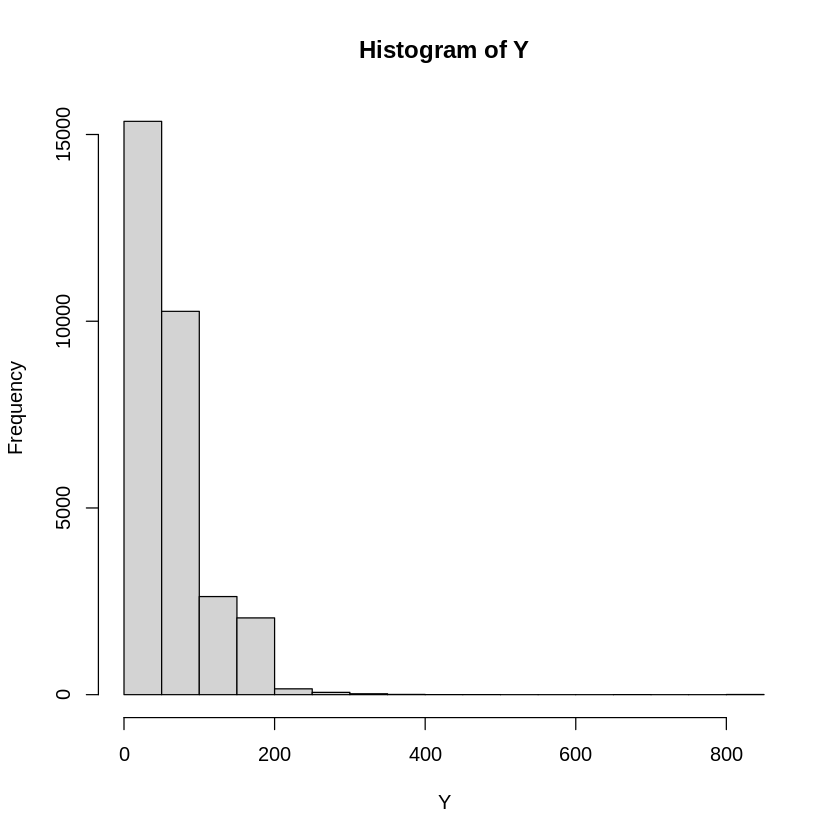

In [42]:
hist(Y)

In [43]:
mean(Y)

[1] 61.14804

In [44]:
var(Y)

[1] 2195.982

### Nomalization

After having tested without normalizing, we realized that the prediction of about all the models were better. So we don't normalize the data, even if the performences were also good when normalizing the data.

But if we decided to normalize, we have to execute the following cells in order to first keep track of the scaling info when submitting the predictions on Zindi and to transform the data

### You can just skip what is commented hereunder, and go to Feature Selection

In [ ]:
# scaling_info <- attributes(scale(Y))

In [ ]:
# scaling_info

In [ ]:
# train_preprocessed <- as.data.frame(scale(train_preprocessed))
# test_preprocessed <- as.data.frame(scale(test_preprocessed))

In [ ]:
# X <- train_preprocessed[,setdiff(colnames(train_preprocessed), "target")]
# Y <- train_preprocessed[,"target"]
# N <- nrow(X)
# n <- ncol(X)

Distribution of the target variable.

In [ ]:
# hist(Y)

In [ ]:
# mean(Y)

In [ ]:
# var(Y)

### Feature Selection

Performing some **feature selection** in order to reduce the dimensionnality of the datasets was also interesting. Indeed the trainning time were very high for some models like the **svm** which took more or less 1H to train using all the features.

First of all, as seen at the beginning the target related variables are just present in the trainning set and not in the test set, so we will just discard them for the trainning of ou models.

In [45]:
train_preprocessed$target_count <- NULL
train_preprocessed$target_variance <- NULL
train_preprocessed$target_max <- NULL
train_preprocessed$target_min <- NULL

#### Correlation matrix

The correlation matrix will help us to reduce dimensionality to identify variables that are highlyCorrelated and that will not give us a lot of information in the prediction phase. What's more, many methods perform better if highly correlated attributes are removed

In [46]:
correlationMatrix <- cor(train_preprocessed)
correlationMatrix

,target,precipitable_water_entire_atmosphere,relative_humidity_2m_above_ground,specific_humidity_2m_above_ground,temperature_2m_above_ground,u_component_of_wind_10m_above_ground,v_component_of_wind_10m_above_ground,L3_NO2_NO2_column_number_density,L3_NO2_NO2_slant_column_number_density,L3_NO2_absorbing_aerosol_index,⋯,L3_SO2_sensor_zenith_angle,L3_SO2_solar_azimuth_angle,L3_SO2_solar_zenith_angle,L3_CH4_CH4_column_volume_mixing_ratio_dry_air,L3_CH4_aerosol_height,L3_CH4_aerosol_optical_depth,L3_CH4_sensor_azimuth_angle,L3_CH4_sensor_zenith_angle,L3_CH4_solar_azimuth_angle,L3_CH4_solar_zenith_angle
target,1.000000000,-0.031328778,-0.084834993,-0.035669511,-0.03881751,-0.1482022734,-0.055100141,0.295235182,0.303844662,0.02924290,⋯,0.0065722740,-0.1615725035,-0.03388793,0.0384229906,0.0376789010,0.044235684,0.006275818,0.0158763316,-0.060384793,0.022139026
precipitable_water_entire_atmosphere,-0.031328778,1.000000000,0.197203378,0.882340986,0.73322529,-0.1951059831,0.032501711,-0.140771400,-0.232103540,0.03656442,⋯,0.0588976765,0.0283366646,-0.45917952,-0.0496015811,-0.0481152775,-0.061706420,-0.005007800,-0.0358284673,0.052388778,-0.089690796
relative_humidity_2m_above_ground,-0.084834993,0.197203378,1.000000000,0.219509095,-0.26063247,0.0111859960,0.118368336,-0.130252959,-0.115285889,-0.05411973,⋯,-0.0181894564,0.0441541889,0.21033914,-0.1203344722,-0.1181140958,-0.128358330,-0.001070169,-0.1098214327,0.097718107,-0.078478677
specific_humidity_2m_above_ground,-0.035669511,0.882340986,0.219509095,1.000000000,0.81627339,-0.1919980450,0.023091326,-0.177695793,-0.242811780,-0.01258157,⋯,0.0694347560,0.0183982712,-0.54311834,-0.0322878970,-0.0336463505,-0.057452819,-0.004422587,-0.0208109567,0.040431529,-0.085647362
temperature_2m_above_ground,-0.038817508,0.733225288,-0.260632472,0.816273387,1.00000000,-0.1436763316,-0.010511310,-0.149736103,-0.233377954,0.03115146,⋯,0.0666439709,0.0063649960,-0.60078813,0.0356286085,0.0327355104,-0.012933708,0.002841321,0.0416432968,-0.009731609,-0.046536367
u_component_of_wind_10m_above_ground,-0.148202273,-0.195105983,0.011185996,-0.191998045,-0.14367633,1.0000000000,0.145513230,-0.041954818,0.001278879,-0.01839962,⋯,-0.0072265494,0.0748762983,0.19608118,-0.0091820238,-0.0094007516,-0.010451744,-0.004631977,-0.0002414211,0.018323976,-0.004132213
v_component_of_wind_10m_above_ground,-0.055100141,0.032501711,0.118368336,0.023091326,-0.01051131,0.1455132297,1.000000000,-0.026074973,-0.027856642,-0.01175571,⋯,-0.0228078816,0.0824118797,0.06818780,-0.0580142115,-0.0573809152,-0.040623544,-0.018153189,-0.0531969218,0.056457103,-0.056239739
L3_NO2_NO2_column_number_density,0.295235182,-0.140771400,-0.130252959,-0.177695793,-0.14973610,-0.0419548183,-0.026074973,1.000000000,0.809810673,-0.18531060,⋯,-0.0031370396,-0.1073406751,0.15467648,-0.0096680791,-0.0101319434,0.029413844,-0.003245631,-0.0205077995,-0.007032756,0.009344310
L3_NO2_NO2_slant_column_number_density,0.303844662,-0.232103540,-0.115285889,-0.242811780,-0.23337795,0.0012788787,-0.027856642,0.809810673,1.000000000,-0.22035449,⋯,0.1115241662,-0.0859519534,0.23891684,0.0034690352,0.0036861556,0.037653228,0.004710166,0.0065498398,-0.015787112,0.033606468
L3_NO2_absorbing_aerosol_index,0.029242898,0.036564421,-0.054119729,-0.012581573,0.03115146,-0.0183996164,-0.011755713,-0.185310598,-0.220354486,1.00000000,⋯,0.1875291473,0.1838911918,-0.11641701,-0.0589509850,-0.0555796957,-0.004503441,-0.021916728,-0.0232476044,0.068852771,-0.075237738


In [47]:
install.packages("caret")
library("caret")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘listenv’, ‘parallelly’, ‘future’, ‘globals’, ‘shape’, ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘prodlim’, ‘proxy’, ‘iterators’, ‘Rcpp’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘timeDate’, ‘e1071’, ‘foreach’, ‘ModelMetrics’, ‘plyr’, ‘pROC’, ‘recipes’, ‘reshape2’


Loading required package: ggplot2

Loading required package: lattice



In general from 0.75 of correlation, the variables are considered as highly correlated.

In [48]:
highlyCorrelated <- findCorrelation(correlationMatrix, cutoff=0.75)

In [49]:
highlyCorrelated

[1] 26 34 16 52 59 68 36  5 58 25 14 22 24 45 41  2  9 32 50 38 57 39 12 37 65
[26] 69 23 49 70 74 31 13 48 47 43  8 60

In [50]:
length(highlyCorrelated)

[1] 37

In [51]:
to_exclude <- names(train_preprocessed)[highlyCorrelated]

In [52]:
to_exclude

[1] "L3_O3_solar_zenith_angle"                       
 [2] "L3_CO_solar_zenith_angle"                       
 [3] "L3_NO2_solar_zenith_angle"                      
 [4] "L3_CLOUD_solar_zenith_angle"                    
 [5] "L3_AER_AI_solar_zenith_angle"                   
 [6] "L3_SO2_solar_zenith_angle"                      
 [7] "L3_HCHO_cloud_fraction"                         
 [8] "temperature_2m_above_ground"                    
 [9] "L3_AER_AI_solar_azimuth_angle"                  
[10] "L3_O3_solar_azimuth_angle"                      
[11] "L3_NO2_sensor_zenith_angle"                     
[12] "L3_O3_cloud_fraction"                           
[13] "L3_O3_sensor_zenith_angle"                      
[14] "L3_CLOUD_cloud_fraction"                        
[15] "L3_HCHO_tropospheric_HCHO_column_number_density"
[16] "precipitable_water_entire_atmosphere"           
[17] "L3_NO2_NO2_slant_column_number_density"         
[18] "L3_CO_sensor_zenith_angle"                      
[19] "L3_CLOUD_sensor_zenith_angle"                   
[20] "L3_HCHO_sensor_zenith_angle"                    
[21] "L3_AER_AI_sensor_zenith_angle"                  
[22] "L3_HCHO_solar_azimuth_angle"                    
[23] "L3_NO2_sensor_altitude"                         
[24] "L3_HCHO_sensor_azimuth_angle"                   
[25] "L3_SO2_sensor_azimuth_angle"                    
[26] "L3_CH4_CH4_column_volume_mixing_ratio_dry_air"  
[27] "L3_O3_sensor_azimuth_angle"                     
[28] "L3_CLOUD_sensor_azimuth_angle"                  
[29] "L3_CH4_aerosol_height"                          
[30] "L3_CH4_solar_azimuth_angle"                     
[31] "L3_CO_sensor_azimuth_angle"                     
[32] "L3_NO2_sensor_azimuth_angle"                    
[33] "L3_CLOUD_cloud_top_pressure"                    
[34] "L3_CLOUD_cloud_top_height"                      
[35] "L3_CLOUD_cloud_base_height"                     
[36] "L3_NO2_NO2_column_number_density"               
[37] "L3_SO2_SO2_column_number_density"

In [53]:
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ lubridate 1.9.3     ✔ tibble    3.2.1
✔ purrr     1.0.2     ✔ tidyr     1.3.1
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ purrr::%||%()   masks base::%||%()
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
✖ purrr::lift()   masks caret::lift()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [54]:
dim(train_preprocessed)

[1] 30557    75

In [55]:
train_preprocessed <- select(train_preprocessed,-c(to_exclude))
test_preprocessed <- select(test_preprocessed,-c(to_exclude))

Warning message:
“Using an external vector in selections was deprecated in tidyselect 1.1.0.
ℹ Please use `all_of()` or `any_of()` instead.
  # Was:
  data %>% select(to_exclude)

  # Now:
  data %>% select(all_of(to_exclude))

See <https://tidyselect.r-lib.org/reference/faq-external-vector.html>.”


In [56]:
dim(train_preprocessed)

[1] 30557    38

In [57]:
dim(test_preprocessed)

[1] 16136    37

In [58]:
X <- train_preprocessed[,setdiff(colnames(train_preprocessed), "target")]
Y <- train_preprocessed[,"target"]
N <- nrow(X)
n <- ncol(X)

There exist many feature selection techniques, so in order to choose which one to apply, we will test different techniques and choose the one that gives the best results.

Next, we will test all combinations of the algorithms we have selected with different feature selection techniques in order to find the best combination that minimises both **NMSE** and **RMSE** to chose the best combination among all.

Chosen models :

* Linear model
* Decision tree
* svm model

# **Task 2** : Validation and model selection

#### Feature selection techniques used :

### 1. PCA (Principal Component Analysis)

#### Compute the Covariance Matrix
\[ $\mathbf{C}$ = $\frac{1}{n-1}$ $\sum_{i=1}^n$ ($\mathbf{z}_i$ - $\mathbf{\bar{z}}$) ($\mathbf{z}_i$ - $\mathbf{\bar{z}}$)$^T$ \]
Where \( $\mathbf{z}_i$ \) is the standardized data vector of the \( $i$ \)-th observation, and \( $\mathbf{\bar{z}}$ \) is the mean vector of the standardized data.

#### Compute the Eigenvalues and Eigenvectors
\[ $\mathbf{C} \mathbf{v} = \lambda \mathbf{v}$ \]
Where \( $\lambda$ \) is an eigenvalue and \( $\mathbf{v}$ \) is the corresponding eigenvector.

#### Transform the Data
\[ $\mathbf{Z} \mathbf{V}$ \]
Where \( $\mathbf{Z}$ \) is the matrix of the standardized data and \( $\mathbf{V}$ \) is the matrix of the selected eigenvectors (principal components).

### 2. Correlation with the Output

The Pearson correlation coefficient between a feature \( $X$ \) and the target variable \( $Y$ \) is given by:

\[ $r_{xy} = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^n (x_i - \bar{x})^2} \sqrt{\sum_{i=1}^n (y_i - \bar{y})^2}}$ \]

Where:
- \( $x_i$ \) and \( $y_i$ \) are the individual sample points of \( $X$ \) and \( $Y$ \).
- \( $\bar{x}$ \) and \( $\bar{y}$ \) are the means of \( $X$ \) and \( $Y$ \).
- \( $n$ \) is the number of samples.

### 3. mRMR (Minimum Redundancy Maximum Relevance)

#### Relevance (measured by mutual information)
\[ $\text{Relevance}(X_i, Y) = I(X_i; Y)$ \]
Where \( $I(X_i; Y)$ \) is the mutual information between feature \( $X_i$ \) and target \( $Y$ \).

#### Redundancy (average mutual information between features)
\[ $\text{Redundancy}(X_i, X_j) = \frac{1}{|S|} \sum_{X_j \in S} I(X_i; X_j)$ \]
Where \( $S$ \) is the set of selected features and \( $I(X_i; X_j)$ \) is the mutual information between features \( $X_i$ \) and \( $X_j$ \).

#### mRMR Criterion
\[ $\text{mRMR} = \max_{X_i \in F - S} \left( I(X_i; Y) - \frac{1}{|S|} \sum_{X_j \in S} I(X_i; X_j) \right)$ \]
Where \( $F$ \) is the set of all features, and \( $S$ \) is the set of already selected features.

#### Metrics used : **RMSE** and **NMSE**

# As you may remark, we included the metrics in almost every model fitting process.the reason is that for some reason we don't know, when you train the models below, you may receive an error indicating that the functions rmse and nmse are not found to fix that we just copied the metrics functions hereunder in each model trainning cell.

In [59]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}

Now using the metrics above, we will compare the performences of three models among the following :

* stats/ridge (linear/ridge models)
* keras (neural networks)
* tree/rpart (decision trees)
* randomForest (random forest)
* RSNNS (radial basis functions)
* lazy (nearest neighbours)
* e1071 (SVM)
* glmnet (LASSO/ElasticNet models)

### Linear Model

##### Single Model

In [60]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}


DS<-cbind(X,target=Y)

lm_model<- lm(target~.,DS)

Y_hat<- predict(lm_model,X)

RMSE <- rmse(Y_hat,Y)
NMSE <- nmse(Y_hat,Y)

print(paste("RMSE=",round(RMSE,digits=4)))
print(paste("NMSE=",round(NMSE,digits=4)))


[1] "RMSE= 38.5976"
[1] "NMSE= 0.6784"


In [61]:
summary(lm_model)


Call:
lm(formula = target ~ ., data = DS)

Residuals:
    Min      1Q  Median      3Q     Max 
-177.01  -24.86   -6.16   16.87  768.28 

Coefficients:
                                                      Estimate Std. Error
(Intercept)                                          3.189e+03  9.237e+01
relative_humidity_2m_above_ground                    2.926e-01  1.627e-02
specific_humidity_2m_above_ground                   -3.537e+03  1.152e+02
u_component_of_wind_10m_above_ground                -1.445e+00  8.655e-02
v_component_of_wind_10m_above_ground                 7.914e-01  8.879e-02
L3_NO2_absorbing_aerosol_index                       2.697e+00  9.007e-01
L3_NO2_cloud_fraction                               -1.075e+01  1.170e+00
L3_NO2_solar_azimuth_angle                           7.391e-03  6.699e-03
L3_NO2_stratospheric_NO2_column_number_density       5.937e+05  3.168e+04
L3_NO2_tropopause_pressure                          -1.002e-03  7.124e-05
L3_NO2_tropospheric_NO2_column_num

### Linear Model - Cross validation : In order to have more realistic results

In [62]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}



CV_folds <- 10

size_CV <-floor(N/CV_folds)

CV_RMSE<-numeric(CV_folds)
CV_NMSE<-numeric(CV_folds)

for (i in 1:CV_folds) {
     idx_ts<-(((i-1)*size_CV+1):(i*size_CV))  ### idx_ts represents the indices of the test set the i-th fold
     X_ts<-X[idx_ts,]
     Y_ts<-Y[idx_ts]

     idx_tr<-setdiff(1:N,idx_ts) ### idx_tr represents  indices of the training sefor the i-th fold
     X_tr<-X[idx_tr,]
     Y_tr<-Y[idx_tr]

     DS<-cbind(X_tr,target=Y_tr)

     # Model fit (using lm function)
     model<- lm(target~., DS)

     # Model prediction
     Y_hat_ts<- predict(model, X_ts)

     # Cross validation error = RMSE
     CV_RMSE[i]<-rmse(Y_hat_ts, Y_ts)
     # Cross validation error = NMSE
     CV_NMSE[i]<-nmse(Y_hat_ts, Y_ts)
}


print(paste("CV error (RMSE)=",round(mean(CV_RMSE),digits=4), " ; std dev=",round(sd(CV_RMSE),digits=4)))
print(paste("CV error (NMSE)=",round(mean(CV_NMSE),digits=4), " ; std dev=",round(sd(CV_NMSE),digits=4)))

[1] "CV error (RMSE)= 38.9827  ; std dev= 4.9815"
[1] "CV error (NMSE)= 0.7223  ; std dev= 0.09"


### Linear Model - Ensemble of models

In [63]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}






CV_folds <- 10
R<-20

size_CV <-floor(N/CV_folds)

CV_RMSE<-numeric(CV_folds)
CV_NMSE<-numeric(CV_folds)

# CV_err<-numeric(CV_folds)

for (i in 1:CV_folds) {
     idx_ts<-(((i-1)*size_CV+1):(i*size_CV))  ### idx_ts represents the indices of the test set the i-th fold
     X_ts<-X[idx_ts,]
     Y_ts<-Y[idx_ts]

     idx_tr<-setdiff(1:N,idx_ts) ### idx_tr represents  indices of the training sefor the i-th fold
     X_tr<-X[idx_tr,]
     Y_tr<-Y[idx_tr]

    # The predictions of each individual model is stored as
    # a column of the Y_hat_ts_ensemble matrix
     Y_hat_ts_ensemble <- matrix(0,nrow=nrow(X_ts),ncol=R)

     for (r in 1:R) {
         idx_tr_resample <- sample(idx_tr,rep=T)
         X_tr<-X[idx_tr_resample,]
         Y_tr<-Y[idx_tr_resample]

         DS<-cbind(X_tr,target=Y_tr)

         # Model fit (using lm function)
         model<- lm(target~.,DS)

         # Storing prediction for the r^th model
         Y_hat_ts_ensemble[,r]<- predict(model,X_ts)

     }

     #Computing ensemble prediction (via model averaging)
     Y_hat_ts<-apply(Y_hat_ts_ensemble,1,mean)

      # Cross validation error = RMSE
     CV_RMSE[i]<-rmse(Y_hat_ts, Y_ts)
     # Cross validation error = NMSE
     CV_NMSE[i]<-nmse(Y_hat_ts, Y_ts)
     }

print(paste("CV error (RMSE)=",round(mean(CV_RMSE),digits=4), " ; std dev=",round(sd(CV_RMSE),digits=4)))
print(paste("CV error (NMSE)=",round(mean(CV_NMSE),digits=4), " ; std dev=",round(sd(CV_NMSE),digits=4)))

[1] "CV error (RMSE)= 38.9957  ; std dev= 4.9928"
[1] "CV error (NMSE)= 0.7227  ; std dev= 0.09"


As we can see for a linear model, the difference between ensmble and single model predictions errors (nmse and rmse) is not too big. Let's try to reduce it by using feature selection techniques.

#### Linear Model -  Correlation with the output

In [64]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}





# drop = F is used to preserve the structure of the data as data.frame (see https://www.r-bloggers.com/2018/02/r-tip-use-drop-false-with-data-frames/)
CV_folds <- 10

size_CV <-floor(N/CV_folds)

CV_RMSE<-matrix(0,nrow=n,ncol=CV_folds)
CV_NMSE<-matrix(0,nrow=n,ncol=CV_folds)

for (i in 1:CV_folds) {

    idx_ts<-(((i-1)*size_CV+1):(i*size_CV))  ### idx_ts represents the indices of the test set the i-th fold
    X_ts<-X[idx_ts,]
    Y_ts<-Y[idx_ts]

    idx_tr<-setdiff(1:N,idx_ts) ### idx_tr represents  indices of the training sefor the i-th fold
    X_tr<-X[idx_tr,]
    Y_tr<-Y[idx_tr]

    # Compute correlation across all the input variables and the target variable
    correlation_vector <-abs(cor(X_tr,Y_tr))
    # Rank variables according to correlation with the output
    lm_correlation_ranking_idx <-sort(correlation_vector,dec=T,index.return=T)$ix

    for (nb_features in 1:n) {
        # Create a dataset including only the nb_features most correlated variables with the output
        DS<-cbind(X_tr[,lm_correlation_ranking_idx[1:nb_features],drop=F],target=Y_tr)

        # Model fit (using lm function)
        model<- lm(target~.,DS)

        # Model prediction
        Y_hat_ts<- predict(model,X_ts[,lm_correlation_ranking_idx[1:nb_features],drop=F])

        CV_RMSE[nb_features,i]<-rmse(Y_hat_ts, Y_ts)
        # Cross validation error = NMSE
        CV_NMSE[nb_features,i]<-nmse(Y_hat_ts, Y_ts)
    }
}

print(paste("#Features: ",c(1:n), " ; CV error (RMSE)=",round(apply(CV_RMSE,1,mean),digits=4), " , std dev=",round(apply(CV_RMSE,1,sd),digits=4)
, " ; CV error (NMSE)=",round(apply(CV_NMSE,1,mean),digits=4), " , std dev=",round(apply(CV_NMSE,1,sd),digits=4)))

 [1] "#Features:  1  ; CV error (RMSE)= 43.8692  , std dev= 5.3491  ; CV error (NMSE)= 0.9121  , std dev= 0.0754" 
 [2] "#Features:  2  ; CV error (RMSE)= 42.8844  , std dev= 5.0714  ; CV error (NMSE)= 0.8737  , std dev= 0.088"  
 [3] "#Features:  3  ; CV error (RMSE)= 42.1183  , std dev= 5.1141  ; CV error (NMSE)= 0.8429  , std dev= 0.0896" 
 [4] "#Features:  4  ; CV error (RMSE)= 41.4739  , std dev= 5.4509  ; CV error (NMSE)= 0.816  , std dev= 0.0879"  
 [5] "#Features:  5  ; CV error (RMSE)= 41.4386  , std dev= 5.446  ; CV error (NMSE)= 0.8147  , std dev= 0.0887"  
 [6] "#Features:  6  ; CV error (RMSE)= 41.4405  , std dev= 5.4618  ; CV error (NMSE)= 0.8147  , std dev= 0.089"  
 [7] "#Features:  7  ; CV error (RMSE)= 41.4403  , std dev= 5.4643  ; CV error (NMSE)= 0.8147  , std dev= 0.0891" 
 [8] "#Features:  8  ; CV error (RMSE)= 41.338  , std dev= 5.4865  ; CV error (NMSE)= 0.8105  , std dev= 0.0887"  
 [9] "#Features:  9  ; CV error (RMSE)= 41.2436  , std dev= 5.5348  ; CV error (

In [65]:
lm_correlation_ranking_idx
colnames(X)[lm_correlation_ranking_idx]

[1] 13 26 18 10 23  7 33  3 17 30  6 22 20 15 21  9 11  1 25 24 29 34  4 19 12
[26]  5  8 37 36  2 31 32 14 28 16 35 27

[1] "L3_CO_CO_column_number_density"                     
 [2] "L3_AER_AI_sensor_altitude"                          
 [3] "L3_HCHO_HCHO_slant_column_number_density"           
 [4] "L3_NO2_tropospheric_NO2_column_number_density"      
 [5] "L3_CLOUD_solar_azimuth_angle"                       
 [6] "L3_NO2_solar_azimuth_angle"                         
 [7] "L3_SO2_solar_azimuth_angle"                         
 [8] "u_component_of_wind_10m_above_ground"               
 [9] "L3_CO_solar_azimuth_angle"                          
[10] "L3_SO2_absorbing_aerosol_index"                     
[11] "L3_NO2_cloud_fraction"                              
[12] "L3_CLOUD_cloud_optical_depth"                       
[13] "L3_HCHO_tropospheric_HCHO_column_number_density_amf"
[14] "L3_CO_cloud_height"                                 
[15] "L3_CLOUD_cloud_base_pressure"                       
[16] "L3_NO2_tropopause_pressure"                         
[17] "L3_O3_O3_column_number_density"                     
[18] "relative_humidity_2m_above_ground"                  
[19] "L3_AER_AI_absorbing_aerosol_index"                  
[20] "L3_CLOUD_surface_albedo"                            
[21] "L3_SO2_SO2_slant_column_number_density"             
[22] "L3_CH4_aerosol_optical_depth"                       
[23] "v_component_of_wind_10m_above_ground"               
[24] "L3_HCHO_solar_zenith_angle"                         
[25] "L3_O3_O3_effective_temperature"                     
[26] "L3_NO2_absorbing_aerosol_index"                     
[27] "L3_NO2_stratospheric_NO2_column_number_density"     
[28] "L3_CH4_solar_zenith_angle"                          
[29] "L3_CH4_sensor_zenith_angle"                         
[30] "specific_humidity_2m_above_ground"                  
[31] "L3_SO2_cloud_fraction"                              
[32] "L3_SO2_sensor_zenith_angle"                         
[33] "L3_CO_H2O_column_number_density"                    
[34] "L3_SO2_SO2_column_number_density_amf"               
[35] "L3_CO_sensor_altitude"                              
[36] "L3_CH4_sensor_azimuth_angle"                        
[37] "L3_AER_AI_sensor_azimuth_angle"

### Linear Model - PCA

In [66]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}





# drop = F is used to preserve the structure of the data as data.frame (see https://www.r-bloggers.com/2018/02/r-tip-use-drop-false-with-data-frames/)
CV_folds <- 10

size_CV <-floor(N/CV_folds)

CV_RMSE<-matrix(0,nrow=n,ncol=CV_folds)
CV_NMSE<-matrix(0,nrow=n,ncol=CV_folds)

# Compute PCA on the full input dataset X and return the dataset transformed in the space of principal components
X_pca<-data.frame(prcomp(X,retx=T)$x)

for (i in 1:CV_folds) {

    idx_ts<-(((i-1)*size_CV+1):(i*size_CV))  ### idx_ts represents the indices of the test set the i-th fold
    X_ts<-X_pca[idx_ts,]
    Y_ts<-Y[idx_ts]

    idx_tr<-setdiff(1:N,idx_ts) ### idx_tr represents  indices of the training sefor the i-th fold
    X_tr<-X_pca[idx_tr,]
    Y_tr<-Y[idx_tr]

    for (nb_components in 1:n) {
        # Create a dataset including only the first nb_components principal components
        DS<-cbind(X_tr[,1:nb_components,drop=F],target=Y_tr)

        # Model fit (using lm function)
        model<- lm(target~.,DS)

        # Model predict
        Y_hat_ts<- predict(model,X_ts[,1:nb_components,drop=F])

        CV_RMSE[nb_components,i]<-rmse(Y_hat_ts, Y_ts)
        # Cross validation error = NMSE
        CV_NMSE[nb_components,i]<-nmse(Y_hat_ts, Y_ts)
    }
}


print(paste("#Features: ",c(1:n), " ; CV error (RMSE)=",round(apply(CV_RMSE,1,mean),digits=4), " , std dev=",round(apply(CV_RMSE,1,sd),digits=4)
, " ; CV error (NMSE)=",round(apply(CV_NMSE,1,mean),digits=4), " , std dev=",round(apply(CV_NMSE,1,sd),digits=4)))


 [1] "#Features:  1  ; CV error (RMSE)= 46.656  , std dev= 5.9264  ; CV error (NMSE)= 1.0285  , std dev= 0.0464"  
 [2] "#Features:  2  ; CV error (RMSE)= 46.4579  , std dev= 5.88  ; CV error (NMSE)= 1.02  , std dev= 0.0511"     
 [3] "#Features:  3  ; CV error (RMSE)= 46.2748  , std dev= 5.8394  ; CV error (NMSE)= 1.0122  , std dev= 0.0532" 
 [4] "#Features:  4  ; CV error (RMSE)= 44.3468  , std dev= 5.3137  ; CV error (NMSE)= 0.9326  , std dev= 0.0795" 
 [5] "#Features:  5  ; CV error (RMSE)= 44.2121  , std dev= 5.3401  ; CV error (NMSE)= 0.9268  , std dev= 0.079"  
 [6] "#Features:  6  ; CV error (RMSE)= 44.2215  , std dev= 5.3353  ; CV error (NMSE)= 0.9273  , std dev= 0.0804" 
 [7] "#Features:  7  ; CV error (RMSE)= 44.1585  , std dev= 5.3393  ; CV error (NMSE)= 0.9248  , std dev= 0.0827" 
 [8] "#Features:  8  ; CV error (RMSE)= 44.1594  , std dev= 5.3384  ; CV error (NMSE)= 0.9248  , std dev= 0.0827" 
 [9] "#Features:  9  ; CV error (RMSE)= 44.1316  , std dev= 5.3569  ; CV error (

#### Linear Model - mRmR

In [67]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}






# drop = F is used to preserve the structure of the data as data.frame (see https://www.r-bloggers.com/2018/02/r-tip-use-drop-false-with-data-frames/)

CV_folds <- 10

size_CV <-floor(N/CV_folds)

CV_RMSE<-matrix(0,nrow=n,ncol=CV_folds)
CV_NMSE<-matrix(0,nrow=n,ncol=CV_folds)

for (i in 1:CV_folds) {

    idx_ts<-(((i-1)*size_CV+1):(i*size_CV))  ### idx_ts represents the indices of the test set the i-th fold
    X_ts<-X[idx_ts,]
    Y_ts<-Y[idx_ts]

    idx_tr<-setdiff(1:N,idx_ts) ### idx_tr represents  indices of the training sefor the i-th fold
    X_tr<-X[idx_tr,]
    Y_tr<-Y[idx_tr]

    # Computing the mutual_info between input variables and output variable on the training set
    mutual_info <- -0.5 * log(1 - cor(X_tr,Y_tr)^2)

    # Initialization : No variables are selected and all the variables are candidates
    selected<-c()
    candidates<-1:n

    #mRMR ranks the variables by taking account not only the mutual_info with the output, but also by avoiding redudant variables
    for (j in 1:n) {
        redundancy_score<-numeric(length(candidates))

        if (length(selected)>0) {
            # Compute the mutual_info between the selected variables and the candidates on the training set
            mutual_info_selected_candidates <- -0.5 * log(1 - cor(X_tr[,selected,drop=F],X_tr[,candidates,drop=F])^2)
            # Compute the mean mutual_info for each candidate variable, across the selected variables
            redundancy_score<-apply(mutual_info_selected_candidates,2,mean)
        }

        # mRMR: minimum Redundancy Maximum Relevancy
        mRMR_score<-mutual_info[candidates]-redundancy_score

        # Select the candidate variable that maximises the mRMR score
        selected_current<-candidates[which.max(mRMR_score)]
        selected<-c(selected,selected_current)

        # Remove the selected variables from the candidates
        candidates<-setdiff(candidates,selected_current)
    }

    ranking <- selected

    for (nb_features in 1:n) {
        # Create a dataset including only the first nb_features selected variables
        DS<-cbind(X_tr[,ranking[1:nb_features],drop=F],target=Y_tr)

        # Model fit (using lm function)
        model<- lm(target~.,DS)

        # Model prediction
        Y_hat_ts<- predict(model,X_ts[,ranking[1:nb_features],drop=F])

        CV_RMSE[nb_features,i]<-rmse(Y_hat_ts, Y_ts)
        # Cross validation error = NMSE
        CV_NMSE[nb_features,i]<-nmse(Y_hat_ts, Y_ts)
    }
}

print(paste("#Features: ",c(1:n), " ; CV error (RMSE)=",round(apply(CV_RMSE,1,mean),digits=4), " , std dev=",round(apply(CV_RMSE,1,sd),digits=4)
, " ; CV error (NMSE)=",round(apply(CV_NMSE,1,mean),digits=4), " , std dev=",round(apply(CV_NMSE,1,sd),digits=4)))


 [1] "#Features:  1  ; CV error (RMSE)= 43.8692  , std dev= 5.3491  ; CV error (NMSE)= 0.9121  , std dev= 0.0754" 
 [2] "#Features:  2  ; CV error (RMSE)= 43.7138  , std dev= 5.5676  ; CV error (NMSE)= 0.9047  , std dev= 0.0742" 
 [3] "#Features:  3  ; CV error (RMSE)= 42.893  , std dev= 5.4136  ; CV error (NMSE)= 0.872  , std dev= 0.0798"   
 [4] "#Features:  4  ; CV error (RMSE)= 41.841  , std dev= 5.3117  ; CV error (NMSE)= 0.8299  , std dev= 0.0774"  
 [5] "#Features:  5  ; CV error (RMSE)= 41.2592  , std dev= 5.6193  ; CV error (NMSE)= 0.8068  , std dev= 0.0886" 
 [6] "#Features:  6  ; CV error (RMSE)= 40.9294  , std dev= 5.739  ; CV error (NMSE)= 0.7938  , std dev= 0.0915"  
 [7] "#Features:  7  ; CV error (RMSE)= 40.6902  , std dev= 5.6347  ; CV error (NMSE)= 0.7846  , std dev= 0.0884" 
 [8] "#Features:  8  ; CV error (RMSE)= 40.6494  , std dev= 5.5948  ; CV error (NMSE)= 0.7829  , std dev= 0.086"  
 [9] "#Features:  9  ; CV error (RMSE)= 40.7327  , std dev= 5.5269  ; CV error (

In [68]:
selected
colnames(X)[selected]

[1] 13 30 26 10 18  3 22 29 20 34 15  7 35  4  1 27 11 21 32 24  8 36 14 33  6
[26] 25 28 19 17 31 12 37  9 23  5  2 16

[1] "L3_CO_CO_column_number_density"                     
 [2] "L3_SO2_absorbing_aerosol_index"                     
 [3] "L3_AER_AI_sensor_altitude"                          
 [4] "L3_NO2_tropospheric_NO2_column_number_density"      
 [5] "L3_HCHO_HCHO_slant_column_number_density"           
 [6] "u_component_of_wind_10m_above_ground"               
 [7] "L3_CLOUD_cloud_optical_depth"                       
 [8] "L3_SO2_SO2_slant_column_number_density"             
 [9] "L3_HCHO_tropospheric_HCHO_column_number_density_amf"
[10] "L3_CH4_aerosol_optical_depth"                       
[11] "L3_CO_cloud_height"                                 
[12] "L3_NO2_solar_azimuth_angle"                         
[13] "L3_CH4_sensor_azimuth_angle"                        
[14] "v_component_of_wind_10m_above_ground"               
[15] "relative_humidity_2m_above_ground"                  
[16] "L3_AER_AI_sensor_azimuth_angle"                     
[17] "L3_O3_O3_column_number_density"                     
[18] "L3_CLOUD_cloud_base_pressure"                       
[19] "L3_SO2_sensor_zenith_angle"                         
[20] "L3_CLOUD_surface_albedo"                            
[21] "L3_NO2_stratospheric_NO2_column_number_density"     
[22] "L3_CH4_sensor_zenith_angle"                         
[23] "L3_CO_H2O_column_number_density"                    
[24] "L3_SO2_solar_azimuth_angle"                         
[25] "L3_NO2_cloud_fraction"                              
[26] "L3_AER_AI_absorbing_aerosol_index"                  
[27] "L3_SO2_SO2_column_number_density_amf"               
[28] "L3_HCHO_solar_zenith_angle"                         
[29] "L3_CO_solar_azimuth_angle"                          
[30] "L3_SO2_cloud_fraction"                              
[31] "L3_O3_O3_effective_temperature"                     
[32] "L3_CH4_solar_zenith_angle"                          
[33] "L3_NO2_tropopause_pressure"                         
[34] "L3_CLOUD_solar_azimuth_angle"                       
[35] "L3_NO2_absorbing_aerosol_index"                     
[36] "specific_humidity_2m_above_ground"                  
[37] "L3_CO_sensor_altitude"

### Decision tree

In [69]:
install.packages("rpart") # to install
library(rpart)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



### Decision Tree Single model

In [79]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}





DS<-cbind(X,target=Y)

tree_model<- rpart(target~.,DS,cp=0)

Y_hat<- predict(tree_model,X)

RMSE <- rmse(Y_hat,Y)
NMSE <- nmse(Y_hat,Y)

print(paste("RMSE=",round(RMSE,digits=4)))
print(paste("NMSE=",round(NMSE,digits=4)))


[1] "RMSE= 23.5582"
[1] "NMSE= 0.2527"


Let's have a look to the performances of the three

In [75]:
printcp(tree_model)


Regression tree:
rpart(formula = target ~ ., data = DS, cp = 0)

Variables actually used in tree construction:
 [1] L3_AER_AI_absorbing_aerosol_index                  
 [2] L3_AER_AI_sensor_altitude                          
 [3] L3_AER_AI_sensor_azimuth_angle                     
 [4] L3_CH4_aerosol_optical_depth                       
 [5] L3_CH4_sensor_azimuth_angle                        
 [6] L3_CH4_sensor_zenith_angle                         
 [7] L3_CH4_solar_zenith_angle                          
 [8] L3_CLOUD_cloud_base_pressure                       
 [9] L3_CLOUD_cloud_optical_depth                       
[10] L3_CLOUD_solar_azimuth_angle                       
[11] L3_CLOUD_surface_albedo                            
[12] L3_CO_cloud_height                                 
[13] L3_CO_CO_column_number_density                     
[14] L3_CO_H2O_column_number_density                    
[15] L3_CO_sensor_altitude                              
[16] L3_CO_solar_azimuth_angle   

##### Parameter tunning

The value of the parameter **cp** allows us to avoid overfitting by controlling the size of the three

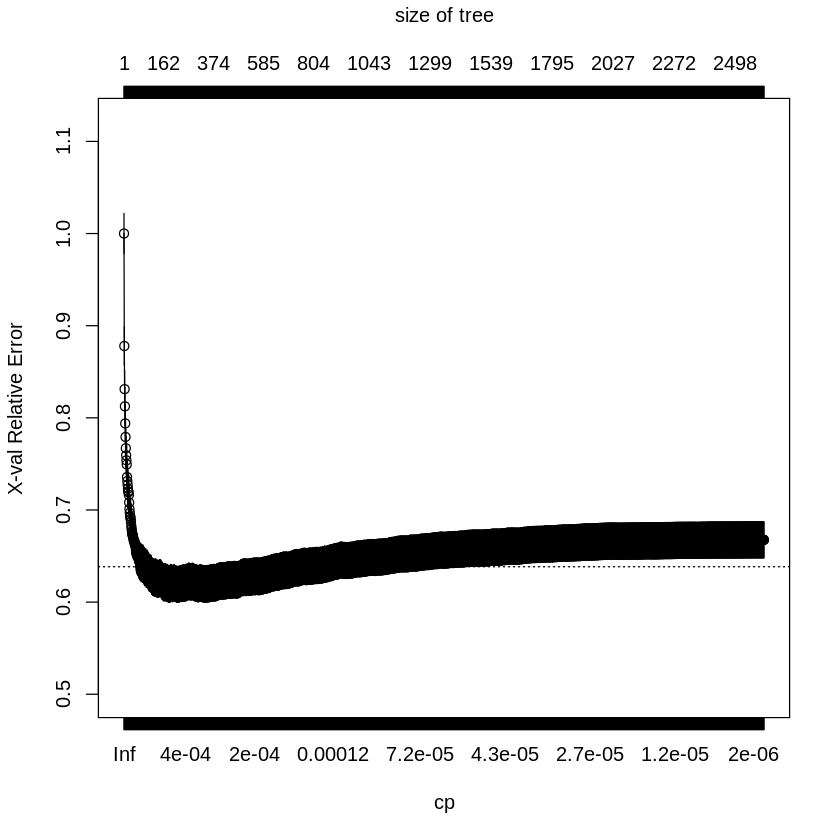

In [74]:
plotcp(tree_model)

Tunning the parameter cp, we will find the value for this parameter that will minimize the error

In [80]:
tree_model$cptable

,CP,nsplit,rel error,xerror,xstd
1,0.123442116,0,1.0000000,1.0001106,0.02175122
2,0.047172175,1,0.8765579,0.8780108,0.02114380
3,0.019534634,2,0.8293857,0.8309787,0.02057256
4,0.018411227,3,0.8098511,0.8103317,0.02052002
5,0.015332440,4,0.7914398,0.7949895,0.02069023
6,0.013023988,5,0.7761074,0.7808540,0.02061410
7,0.008950072,6,0.7630834,0.7669501,0.02063346
8,0.008829207,7,0.7541333,0.7622614,0.02034677
9,0.008420782,8,0.7453041,0.7534911,0.02057859
10,0.008313366,9,0.7368834,0.7484114,0.02054496


In [76]:
cp <- as.numeric(tree_model$cptable[which.min(tree_model$cptable[,4]),][1])

In [77]:
cp

[1] 0.0004460168

Now let's check if the results are improved

In [81]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}

DS<-cbind(X,target=Y)

tree_model<- rpart(target~.,DS, cp=cp)

Y_hat<- predict(tree_model,X)

RMSE <- rmse(Y_hat,Y)
NMSE <- nmse(Y_hat,Y)

print(paste("RMSE=",round(RMSE,digits=4)))
print(paste("NMSE=",round(NMSE,digits=4)))


[1] "RMSE= 32.3262"
[1] "NMSE= 0.4759"


######Importance of the variables

In [111]:
tree_model$variable.importance

L3_CO_CO_column_number_density 
                                        10306601.01 
                          L3_AER_AI_sensor_altitude 
                                         6988197.05 
                              L3_CO_sensor_altitude 
                                         5494144.48 
                  specific_humidity_2m_above_ground 
                                         4730338.22 
           L3_HCHO_HCHO_slant_column_number_density 
                                         3858872.72 
                         L3_HCHO_solar_zenith_angle 
                                         3102475.21 
                    L3_CO_H2O_column_number_density 
                                         2240447.33 
                       L3_CLOUD_solar_azimuth_angle 
                                         1864757.29 
               u_component_of_wind_10m_above_ground 
                                         1819134.30 
L3_HCHO_tropospheric_HCHO_column_number_density_amf 
                                         1801969.66 
                         L3_NO2_tropopause_pressure 
                                         1764011.42 
                          L3_CO_solar_azimuth_angle 
                                         1612357.54 
               v_component_of_wind_10m_above_ground 
                                         1549341.11 
      L3_NO2_tropospheric_NO2_column_number_density 
                                         1511682.34 
                     L3_O3_O3_column_number_density 
                                         1324363.24 
                            L3_CLOUD_surface_albedo 
                                         1270043.02 
                         L3_NO2_solar_azimuth_angle 
                                         1251125.57 
                     L3_O3_O3_effective_temperature 
                                         1179790.43 
                       L3_CLOUD_cloud_optical_depth 
                                         1148977.70 
                         L3_SO2_solar_azimuth_angle 
                                         1064234.14 
                  L3_AER_AI_absorbing_aerosol_index 
                                          853738.76 
     L3_NO2_stratospheric_NO2_column_number_density 
                                          825762.48 
                              L3_NO2_cloud_fraction 
                                          793777.63 
                  relative_humidity_2m_above_ground 
                                          791427.47 
               L3_SO2_SO2_column_number_density_amf 
                                          756904.39 
                       L3_CLOUD_cloud_base_pressure 
                                          661262.81 
                     L3_SO2_absorbing_aerosol_index 
                                          622508.68 
                     L3_NO2_absorbing_aerosol_index 
                                          591706.19 
                              L3_SO2_cloud_fraction 
                                          526591.14 
                          L3_CH4_solar_zenith_angle 
                                          439947.88 
                                 L3_CO_cloud_height 
                                          348838.86 
                        L3_CH4_sensor_azimuth_angle 
                                          336689.50 
                       L3_CH4_aerosol_optical_depth 
                                          277761.21 
                         L3_CH4_sensor_zenith_angle 
                                          222224.34 
                     L3_AER_AI_sensor_azimuth_angle 
                                          130486.57 
                         L3_SO2_sensor_zenith_angle 
                                          130011.25 
             L3_SO2_SO2_slant_column_number_density 
                                           66951.46

##### Plot of the tree

In [106]:
install.packages("rpart.plot")
library(rpart.plot)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



Warning message:
“labs do not fit even at cex 0.15, there may be some overplotting”


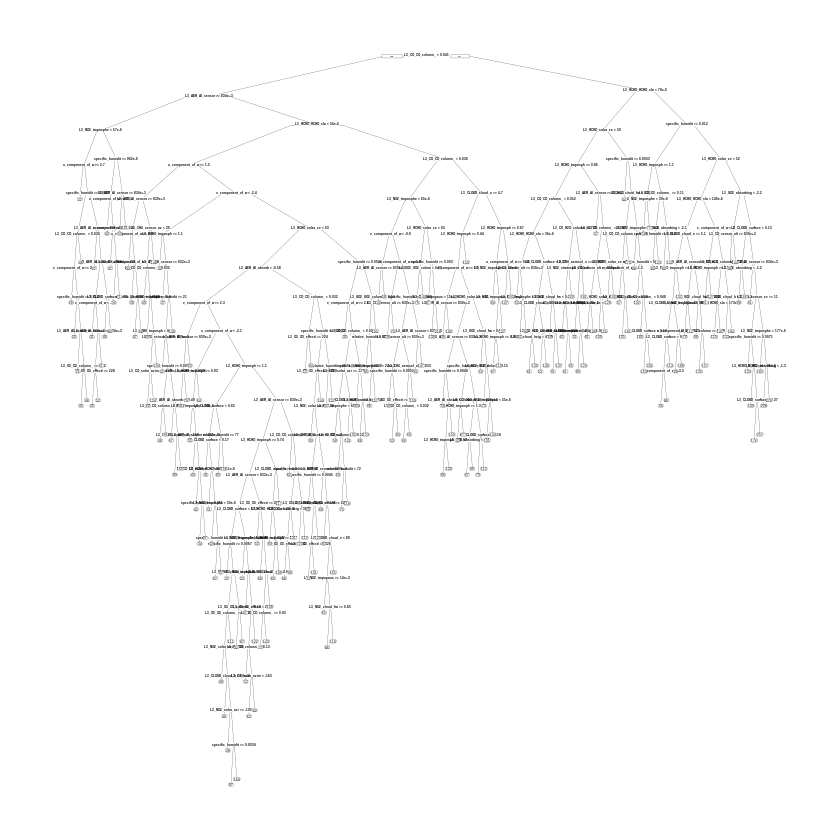

In [110]:
prp(tree_model)

We see an increase that could tell us that the previous decision three was basically overfitting since the error was very low.

### Decision Tree Cross validation

In [112]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}


CV_folds <- 10

size_CV <-floor(N/CV_folds)

CV_RMSE<-numeric(CV_folds)
CV_NMSE<-numeric(CV_folds)

for (i in 1:CV_folds) {
     idx_ts<-(((i-1)*size_CV+1):(i*size_CV))  ### idx_ts represents the indices of the test set the i-th fold
     X_ts<-X[idx_ts,]
     Y_ts<-Y[idx_ts]

     idx_tr<-setdiff(1:N,idx_ts) ### idx_tr represents  indices of the training sefor the i-th fold
     X_tr<-X[idx_tr,]
     Y_tr<-Y[idx_tr]

     DS<-cbind(X_tr,target=Y_tr)

     model<- rpart(target~.,DS,cp=cp)

     # Model prediction
     Y_hat_ts<- predict(model,X_ts)

     # Cross validation error = RMSE
     CV_RMSE[i]<-rmse(Y_hat_ts, Y_ts)
     # Cross validation error = NMSE
     CV_NMSE[i]<-nmse(Y_hat_ts, Y_ts)
}


print(paste("CV error (RMSE)=",round(mean(CV_RMSE),digits=4), " ; std dev=",round(sd(CV_RMSE),digits=4)))
print(paste("CV error (NMSE)=",round(mean(CV_NMSE),digits=4), " ; std dev=",round(sd(CV_NMSE),digits=4)))

[1] "CV error (RMSE)= 39.5578  ; std dev= 4.7548"
[1] "CV error (NMSE)= 0.7442  ; std dev= 0.0847"


### Decision Tree - ensemble model

+/- 21 minutes

In [113]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}






CV_folds <- 10
R<-20

size_CV <-floor(N/CV_folds)

CV_RMSE<-numeric(CV_folds)
CV_NMSE<-numeric(CV_folds)


for (i in 1:CV_folds) {
     idx_ts<-(((i-1)*size_CV+1):(i*size_CV))  ### idx_ts represents the indices of the test set the i-th fold
     X_ts<-X[idx_ts,]
     Y_ts<-Y[idx_ts]

     idx_tr<-setdiff(1:N,idx_ts) ### idx_tr represents  indices of the training sefor the i-th fold
     X_tr<-X[idx_tr,]
     Y_tr<-Y[idx_tr]

    # The predictions of each individual model is stored as
    # a column of the Y_hat_ts_ensemble matrix
     Y_hat_ts_ensemble <- matrix(0,nrow=nrow(X_ts),ncol=R)

     for (r in 1:R) {
         idx_tr_resample <- sample(idx_tr,rep=T)
         X_tr<-X[idx_tr_resample,]
         Y_tr<-Y[idx_tr_resample]

         DS<-cbind(X_tr,target=Y_tr)

         model<- rpart(target~.,DS, cp=cp)

         # Storing prediction for the r^th model
         Y_hat_ts_ensemble[,r]<- predict(model,X_ts)

     }

     #Computing ensemble prediction (via model averaging)
     Y_hat_ts<-apply(Y_hat_ts_ensemble,1,mean)


      # Cross validation error = RMSE
     CV_RMSE[i]<-rmse(Y_hat_ts, Y_ts)
     # Cross validation error = NMSE
     CV_NMSE[i]<-nmse(Y_hat_ts, Y_ts)
     }

print(paste("CV error (RMSE)=",round(mean(CV_RMSE),digits=4), " ; std dev=",round(sd(CV_RMSE),digits=4)))
print(paste("CV error (NMSE)=",round(mean(CV_NMSE),digits=4), " ; std dev=",round(sd(CV_NMSE),digits=4)))

[1] "CV error (RMSE)= 35.4117  ; std dev= 4.6773"
[1] "CV error (NMSE)= 0.5952  ; std dev= 0.0728"


For the next methods, we will restrict to the top 10 most relevant features since it takes a lot of time.

### Decision Tree - mRmR

In [114]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}





# drop = F is used to preserve the structure of the data as data.frame (see https://www.r-bloggers.com/2018/02/r-tip-use-drop-false-with-data-frames/)

CV_folds <- 10
n_variables <- 10

size_CV <-floor(N/CV_folds)

CV_RMSE<-matrix(0,nrow=n_variables,ncol=CV_folds)
CV_NMSE<-matrix(0,nrow=n_variables,ncol=CV_folds)

for (i in 1:CV_folds) {

    idx_ts<-(((i-1)*size_CV+1):(i*size_CV))  ### idx_ts represents the indices of the test set the i-th fold
    X_ts<-X[idx_ts,]
    Y_ts<-Y[idx_ts]

    idx_tr<-setdiff(1:N,idx_ts) ### idx_tr represents  indices of the training sefor the i-th fold
    X_tr<-X[idx_tr,]
    Y_tr<-Y[idx_tr]

    # Computing the mutual_info between input variables and output variable on the training set
    mutual_info <- -0.5 * log(1 - cor(X_tr,Y_tr)^2)

    # Initialization : No variables are selected and all the variables are candidates
    selected<-c()
    candidates<-1:n

    #mRMR ranks the variables by taking account not only the mutual_info with the output, but also by avoiding redudant variables
    for (j in 1:n_variables) {
        redundancy_score<-numeric(length(candidates))

        if (length(selected)>0) {
            # Compute the mutual_info between the selected variables and the candidates on the training set
            mutual_info_selected_candidates <- -0.5 * log(1 - cor(X_tr[,selected,drop=F],X_tr[,candidates,drop=F])^2)
            # Compute the mean mutual_info for each candidate variable, across the selected variables
            redundancy_score<-apply(mutual_info_selected_candidates,2,mean)
        }

        # mRMR: minimum Redundancy Maximum Relevancy
        mRMR_score<-mutual_info[candidates]-redundancy_score

        # Select the candidate variable that maximises the mRMR score
        selected_current<-candidates[which.max(mRMR_score)]
        selected<-c(selected,selected_current)

        # Remove the selected variables from the candidates
        candidates<-setdiff(candidates,selected_current)
    }

    ranking <- selected

    for (nb_features in 1:n_variables) {
        # Create a dataset including only the first nb_features selected variables
        DS<-cbind(X_tr[,ranking[1:nb_features],drop=F],target=Y_tr)

        # Model fit (using lm function)
        model<- rpart(target~.,DS, cp=cp)

        # Model prediction
        Y_hat_ts<- predict(model,X_ts)

        CV_RMSE[nb_features,i]<-rmse(Y_hat_ts, Y_ts)
        # Cross validation error = NMSE
        CV_NMSE[nb_features,i]<-nmse(Y_hat_ts, Y_ts)
    }
}

print(paste("#Features: ",c(1:n_variables), " ; CV error (RMSE)=",round(apply(CV_RMSE,1,mean),digits=4), " , std dev=",round(apply(CV_RMSE,1,sd),digits=4)
, " ; CV error (NMSE)=",round(apply(CV_NMSE,1,mean),digits=4), " , std dev=",round(apply(CV_NMSE,1,sd),digits=4)))


 [1] "#Features:  1  ; CV error (RMSE)= 43.2193  , std dev= 5.2223  ; CV error (NMSE)= 0.8862  , std dev= 0.0793" 
 [2] "#Features:  2  ; CV error (RMSE)= 42.7175  , std dev= 5.3613  ; CV error (NMSE)= 0.8676  , std dev= 0.1013" 
 [3] "#Features:  3  ; CV error (RMSE)= 42.194  , std dev= 4.4643  ; CV error (NMSE)= 0.8496  , std dev= 0.0975"  
 [4] "#Features:  4  ; CV error (RMSE)= 41.1304  , std dev= 5.0467  ; CV error (NMSE)= 0.802  , std dev= 0.0721"  
 [5] "#Features:  5  ; CV error (RMSE)= 40.3028  , std dev= 4.9894  ; CV error (NMSE)= 0.7711  , std dev= 0.081"  
 [6] "#Features:  6  ; CV error (RMSE)= 39.8332  , std dev= 4.9879  ; CV error (NMSE)= 0.7521  , std dev= 0.0723" 
 [7] "#Features:  7  ; CV error (RMSE)= 39.7693  , std dev= 4.9342  ; CV error (NMSE)= 0.7505  , std dev= 0.0758" 
 [8] "#Features:  8  ; CV error (RMSE)= 39.7652  , std dev= 4.8723  ; CV error (NMSE)= 0.7506  , std dev= 0.0764" 
 [9] "#Features:  9  ; CV error (RMSE)= 39.6362  , std dev= 4.9617  ; CV error (

### Decision Tree-PCA

In [116]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}




# drop = F is used to preserve the structure of the data as data.frame (see https://www.r-bloggers.com/2018/02/r-tip-use-drop-false-with-data-frames/)
CV_folds <- 10
n_variables <- 10


size_CV <-floor(N/CV_folds)

CV_RMSE<-matrix(0,nrow=n_variables,ncol=CV_folds)
CV_NMSE<-matrix(0,nrow=n_variables,ncol=CV_folds)

# Compute PCA on the full input dataset X and return the dataset transformed in the space of principal components
X_pca<-data.frame(prcomp(X,retx=T)$x)

for (i in 1:CV_folds) {

    idx_ts<-(((i-1)*size_CV+1):(i*size_CV))  ### idx_ts represents the indices of the test set the i-th fold
    X_ts<-X_pca[idx_ts,]
    Y_ts<-Y[idx_ts]

    idx_tr<-setdiff(1:N,idx_ts) ### idx_tr represents  indices of the training sefor the i-th fold
    X_tr<-X_pca[idx_tr,]
    Y_tr<-Y[idx_tr]

    for (nb_components in 1:n_variables) {
        # Create a dataset including only the first nb_components principal components
        DS<-cbind(X_tr[,1:nb_components,drop=F],target=Y_tr)

        model<- rpart(target~.,DS, cp=cp)

        # Model predict
        Y_hat_ts<- predict(model,X_ts[,1:nb_components,drop=F])

        CV_RMSE[nb_components,i]<-rmse(Y_hat_ts, Y_ts)
        # Cross validation error = NMSE
        CV_NMSE[nb_components,i]<-nmse(Y_hat_ts, Y_ts)
    }
}


print(paste("#Features: ",c(1:n_variables), " ; CV error (RMSE)=",round(apply(CV_RMSE,1,mean),digits=4), " , std dev=",round(apply(CV_RMSE,1,sd),digits=4)
, " ; CV error (NMSE)=",round(apply(CV_NMSE,1,mean),digits=4), " , std dev=",round(apply(CV_NMSE,1,sd),digits=4)))


 [1] "#Features:  1  ; CV error (RMSE)= 44.8081  , std dev= 5.5407  ; CV error (NMSE)= 0.9518  , std dev= 0.0894" 
 [2] "#Features:  2  ; CV error (RMSE)= 45.2293  , std dev= 5.2473  ; CV error (NMSE)= 0.9718  , std dev= 0.0972" 
 [3] "#Features:  3  ; CV error (RMSE)= 45.084  , std dev= 5.4707  ; CV error (NMSE)= 0.9647  , std dev= 0.0978"  
 [4] "#Features:  4  ; CV error (RMSE)= 44.8898  , std dev= 5.5846  ; CV error (NMSE)= 0.9568  , std dev= 0.1082" 
 [5] "#Features:  5  ; CV error (RMSE)= 44.5046  , std dev= 5.3951  ; CV error (NMSE)= 0.9405  , std dev= 0.1013" 
 [6] "#Features:  6  ; CV error (RMSE)= 44.8364  , std dev= 5.2037  ; CV error (NMSE)= 0.9553  , std dev= 0.0989" 
 [7] "#Features:  7  ; CV error (RMSE)= 44.805  , std dev= 5.2531  ; CV error (NMSE)= 0.9545  , std dev= 0.1078"  
 [8] "#Features:  8  ; CV error (RMSE)= 44.9211  , std dev= 5.1833  ; CV error (NMSE)= 0.9598  , std dev= 0.1074" 
 [9] "#Features:  9  ; CV error (RMSE)= 44.8083  , std dev= 5.3883  ; CV error (

#### Decision Tree-Correlaion with output

In [117]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}




# drop = F is used to preserve the structure of the data as data.frame (see https://www.r-bloggers.com/2018/02/r-tip-use-drop-false-with-data-frames/)
CV_folds <- 10
n_variables <- 10

size_CV <-floor(N/CV_folds)

# CV_err<-matrix(0,nrow=n,ncol=CV_folds)

CV_RMSE<-matrix(0,nrow=n_variables,ncol=CV_folds)
CV_NMSE<-matrix(0,nrow=n_variables,ncol=CV_folds)

for (i in 1:CV_folds) {

    idx_ts<-(((i-1)*size_CV+1):(i*size_CV))  ### idx_ts represents the indices of the test set the i-th fold
    X_ts<-X[idx_ts,]
    Y_ts<-Y[idx_ts]

    idx_tr<-setdiff(1:N,idx_ts) ### idx_tr represents  indices of the training sefor the i-th fold
    X_tr<-X[idx_tr,]
    Y_tr<-Y[idx_tr]

    # Compute correlation across all the input variables and the target variable
    correlation_vector <-abs(cor(X_tr,Y_tr))
    # Rank variables according to correlation with the output
    tree_correlation_ranking_idx <-sort(correlation_vector,dec=T,index.return=T)$ix

    for (nb_features in 1:n_variables) {
        # Create a dataset including only the nb_features most correlated variables with the output
        DS<-cbind(X_tr[,tree_correlation_ranking_idx[1:nb_features],drop=F],target=Y_tr)

        # Model fit (using lm function)
        model<- rpart(target~.,DS, cp=cp)

        # Model prediction
        Y_hat_ts<- predict(model,X_ts[,tree_correlation_ranking_idx[1:nb_features],drop=F])

        CV_RMSE[nb_features,i]<-rmse(Y_hat_ts, Y_ts)
        CV_NMSE[nb_features,i]<-nmse(Y_hat_ts, Y_ts)
    }
}

print(paste("#Features: ",c(1:n_variables), " ; CV error (RMSE)=",round(apply(CV_RMSE,1,mean),digits=4), " , std dev=",round(apply(CV_RMSE,1,sd),digits=4)
, " ; CV error (NMSE)=",round(apply(CV_NMSE,1,mean),digits=4), " , std dev=",round(apply(CV_NMSE,1,sd),digits=4)))


 [1] "#Features:  1  ; CV error (RMSE)= 43.2193  , std dev= 5.2223  ; CV error (NMSE)= 0.8862  , std dev= 0.0793" 
 [2] "#Features:  2  ; CV error (RMSE)= 42.0515  , std dev= 5.2222  ; CV error (NMSE)= 0.8402  , std dev= 0.1049" 
 [3] "#Features:  3  ; CV error (RMSE)= 41.2439  , std dev= 5.1485  ; CV error (NMSE)= 0.8078  , std dev= 0.0953" 
 [4] "#Features:  4  ; CV error (RMSE)= 40.7419  , std dev= 5.148  ; CV error (NMSE)= 0.7875  , std dev= 0.085"   
 [5] "#Features:  5  ; CV error (RMSE)= 40.7882  , std dev= 5.2286  ; CV error (NMSE)= 0.7879  , std dev= 0.0719" 
 [6] "#Features:  6  ; CV error (RMSE)= 40.937  , std dev= 5.2014  ; CV error (NMSE)= 0.7939  , std dev= 0.0719"  
 [7] "#Features:  7  ; CV error (RMSE)= 40.9484  , std dev= 5.2984  ; CV error (NMSE)= 0.7941  , std dev= 0.0752" 
 [8] "#Features:  8  ; CV error (RMSE)= 40.2412  , std dev= 4.8716  ; CV error (NMSE)= 0.7693  , std dev= 0.0821" 
 [9] "#Features:  9  ; CV error (RMSE)= 40.1641  , std dev= 5.0455  ; CV error (

### Support Vector Machine (SVM)

In [118]:
install.packages("e1071")
library(e1071)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



### SVM Single model

+/- 12 minutes of execution time.

In [119]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}



DS<-cbind(X,target=Y)

svm_model<- svm(target~.,DS)


Y_hat<- predict(svm_model,X)

RMSE <- rmse(Y_hat,Y)
NMSE <- nmse(Y_hat,Y)

print(paste("RMSE=",round(RMSE,digits=4)))
print(paste("NMSE=",round(NMSE,digits=4)))


[1] "RMSE= 30.074"
[1] "NMSE= 0.4119"


### SVM Cross validation

about 1 hours of execution time.

In [ ]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}






CV_folds <- 10

size_CV <-floor(N/CV_folds)

CV_RMSE<-numeric(CV_folds)
CV_NMSE<-numeric(CV_folds)

for (i in 1:CV_folds) {
     idx_ts<-(((i-1)*size_CV+1):(i*size_CV))  ### idx_ts represents the indices of the test set the i-th fold
     X_ts<-X[idx_ts,]
     Y_ts<-Y[idx_ts]

     idx_tr<-setdiff(1:N,idx_ts) ### idx_tr represents  indices of the training sefor the i-th fold
     X_tr<-X[idx_tr,]
     Y_tr<-Y[idx_tr]

     DS<-cbind(X_tr,target=Y_tr)

     svm_model<- svm(target~.,DS)

     # Model prediction
     Y_hat_ts<- predict(svm_model,X_ts)

     # Cross validation error = RMSE
     CV_RMSE[i]<-rmse(Y_hat_ts, Y_ts)
     # Cross validation error = NMSE
     CV_NMSE[i]<-nmse(Y_hat_ts, Y_ts)
}


print(paste("CV error (RMSE)=",round(mean(CV_RMSE),digits=4), " ; std dev=",round(sd(CV_RMSE),digits=4)))
print(paste("CV error (NMSE)=",round(mean(CV_NMSE),digits=4), " ; std dev=",round(sd(CV_NMSE),digits=4)))

[1] "CV error (RMSE)= 34.3216  ; std dev= 4.6978"
[1] "CV error (NMSE)= 0.5584  ; std dev= 0.0676"


Indeed cross validation gives more accurate results in terms of the predictions performance.

Using the two metrics RMSE and NMSE, the SVM model seems to offer the best performances, followed by the the linear model followed by decision tree

# Task 3 : Other learning Algorithm **xgboost**

+/- 9 minutes of execution time.

In [120]:
install.packages("xgboost")
install.packages("rsample")
library(xgboost)
library(rsample)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘warp’, ‘furrr’, ‘slider’



Attaching package: ‘xgboost’


The following object is masked from ‘package:dplyr’:

    slice



Attaching package: ‘rsample’


The following object is masked from ‘package:e1071’:

    permutations




In [121]:
#splitting into train and test
data.idx <- sample(1:nrow(X))
split <- floor(nrow(X)*0.665)

#train data
xgbtrain.x <- X[data.idx[1:split],]
xgbtrain.y <- Y[data.idx[1:split]]


#test data
xgbtest.x <- X[(data.idx[split]+1):nrow(X),]
xgbtest.y <- Y[(data.idx[split]+1):nrow(X)]

Set the parameters

In [122]:
param <- list("objective"="reg:squarederror",
             "eval_metric"="rmse",
             "nthread"=8,
             "max_depth"=30,
             "eta"=0.1,
             "gamma"=0,
             "subsample"=0.7,
             "colsample_bytree"=1,
             "min_child_weight"=12
             )


model Cross-validation

In [123]:
cv.nround <- 200
xgbmodel.cv <- xgb.cv(param=param,
                    data=data.matrix(xgbtrain.x),
                    label=data.matrix(xgbtrain.y),
                    nfold=3,
                    nround=cv.nround,
                    prediction=T
                    )

[1]	train-rmse:70.720064+0.915448	test-rmse:71.103865+1.919410 
[2]	train-rmse:65.220809+0.943988	test-rmse:66.018924+1.977805 
[3]	train-rmse:60.267113+0.965979	test-rmse:61.532539+2.081684 
[4]	train-rmse:55.865599+1.014369	test-rmse:57.572492+2.161551 
[5]	train-rmse:51.884889+1.024543	test-rmse:54.094181+2.251847 
[6]	train-rmse:48.307619+1.049595	test-rmse:51.022971+2.371727 
[7]	train-rmse:45.113151+1.073096	test-rmse:48.352961+2.464198 
[8]	train-rmse:42.222515+1.107331	test-rmse:46.052188+2.553139 
[9]	train-rmse:39.634904+1.145031	test-rmse:44.020415+2.641717 
[10]	train-rmse:37.315785+1.198047	test-rmse:42.281597+2.737245 
[11]	train-rmse:35.239958+1.243156	test-rmse:40.786938+2.809883 
[12]	train-rmse:33.346070+1.283968	test-rmse:39.456122+2.865330 
[13]	train-rmse:31.656287+1.329889	test-rmse:38.331543+2.914688 
[14]	train-rmse:30.123822+1.376621	test-rmse:37.361471+2.978981 
[15]	train-rmse:28.758259+1.418911	test-rmse:36.536140+3.023999 
[16]	train-rmse:27.500558+1.449942

Hyper-parameters tunning

In [124]:
min.rmse.idx <- which.min(xgbmodel.cv$evaluation_log[,test_rmse_mean])
cat ("Minimum rmse occurred in round : ", min.rmse.idx, "\n")

# Minimum rmse
print(xgbmodel.cv$evaluation_log[min.rmse.idx,])

Minimum rmse occurred in round :  169 
    iter train_rmse_mean train_rmse_std test_rmse_mean test_rmse_std
   <num>           <num>          <num>          <num>         <num>
1:   169        5.892996       2.423847       30.89558      3.151183


In [125]:
xgb_model <- xgboost(param=param,
                    data=data.matrix(xgbtrain.x),
                    label=data.matrix(xgbtrain.y),
                    nrounds = min.rmse.idx,
)

[1]	train-rmse:70.708527 
[2]	train-rmse:65.137242 
[3]	train-rmse:60.187427 
[4]	train-rmse:55.739728 
[5]	train-rmse:51.769750 
[6]	train-rmse:48.178985 
[7]	train-rmse:44.955530 
[8]	train-rmse:42.078351 
[9]	train-rmse:39.467597 
[10]	train-rmse:37.167166 
[11]	train-rmse:35.077405 
[12]	train-rmse:33.149734 
[13]	train-rmse:31.448989 
[14]	train-rmse:29.946657 
[15]	train-rmse:28.577821 
[16]	train-rmse:27.334738 
[17]	train-rmse:26.183272 
[18]	train-rmse:25.133924 
[19]	train-rmse:24.199819 
[20]	train-rmse:23.366279 
[21]	train-rmse:22.625549 
[22]	train-rmse:21.906632 
[23]	train-rmse:21.254518 
[24]	train-rmse:20.629040 
[25]	train-rmse:20.071675 
[26]	train-rmse:19.557369 
[27]	train-rmse:19.068696 
[28]	train-rmse:18.590066 
[29]	train-rmse:18.199076 
[30]	train-rmse:17.832409 
[31]	train-rmse:17.447891 
[32]	train-rmse:17.121128 
[33]	train-rmse:16.815405 
[34]	train-rmse:16.491990 
[35]	train-rmse:16.190131 
[36]	train-rmse:15.915451 
[37]	train-rmse:15.663445 
[38]	train

In [126]:
rmse <- function(m, o) { # m is the value obtained by our model, o is the value actually observed
  return (sqrt(mean((o - m)^2)))
}

nmse <- function(m, o) {
  # Calculate the mean of the true values
  o_mean <- mean(o)

  # Calculate the numerator: sum of squared differences between true and predicted values
  numerator <- sum((o - m)^2)

  # Calculate the denominator: sum of squared differences between true values and mean
  denominator <- sum((o - o_mean)^2)

  # Calculate NMSE
  nmse <- numerator / denominator

  return(nmse)
}

Y_hat <- predict(xgb_model, data.matrix(xgbtest.x))
Y_test <- xgbtest.y
rmse(Y_hat, Y_test)
nmse(Y_hat, Y_test)

[1] 17.62775

[1] 0.1253386

# **Task 4** : Submission on Zindi

**Warning** : the images must be in the current directory, otherwise you will have an error

### Results without normalization of the data :

**Without** normalisation the got the following ranking :

1.   SVM
2.   XGB
3.   Linear model
4.   Decision Tree



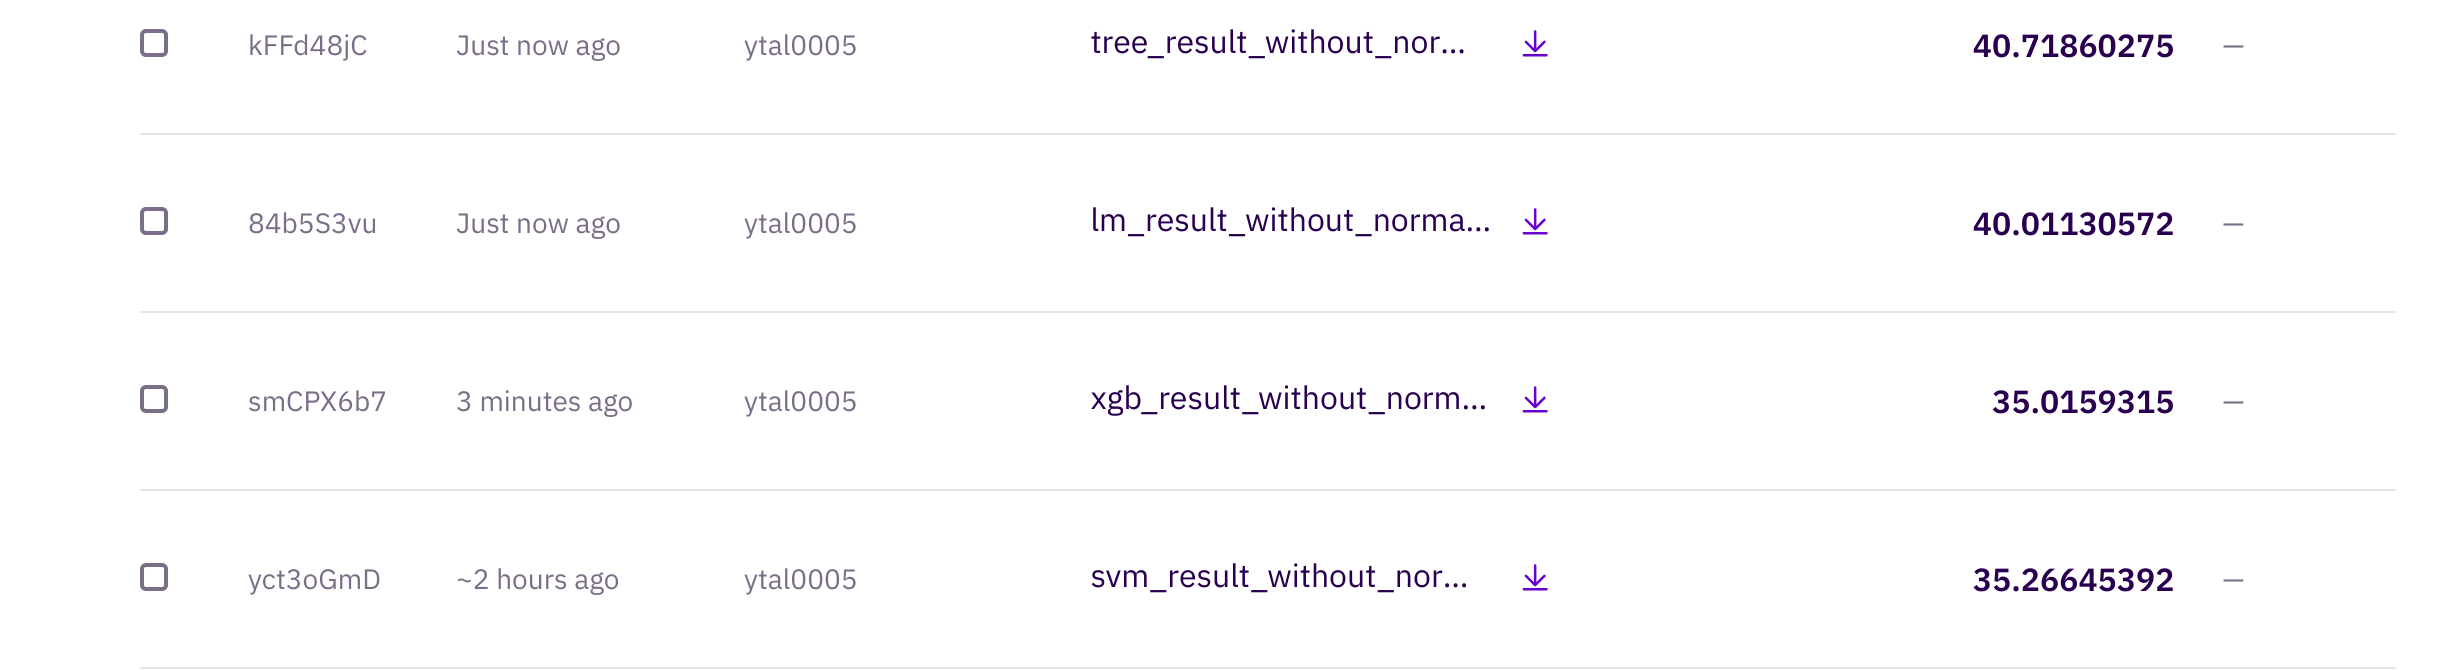

In [ ]:
# library(IRdisplay)
# display_jpeg(file = 'model-results-without-normalization.png')

The model that we decided to chose for the submission is the **xgb** model which gave the best results
---

In order to see the impact that normalization can have on the final prediction, have a look the following

### Results with normalization of the data :

**With** normalisation the got the following ranking :

1.   XGB
2.   SVM
3.   Linear model
4.   Decision Tree

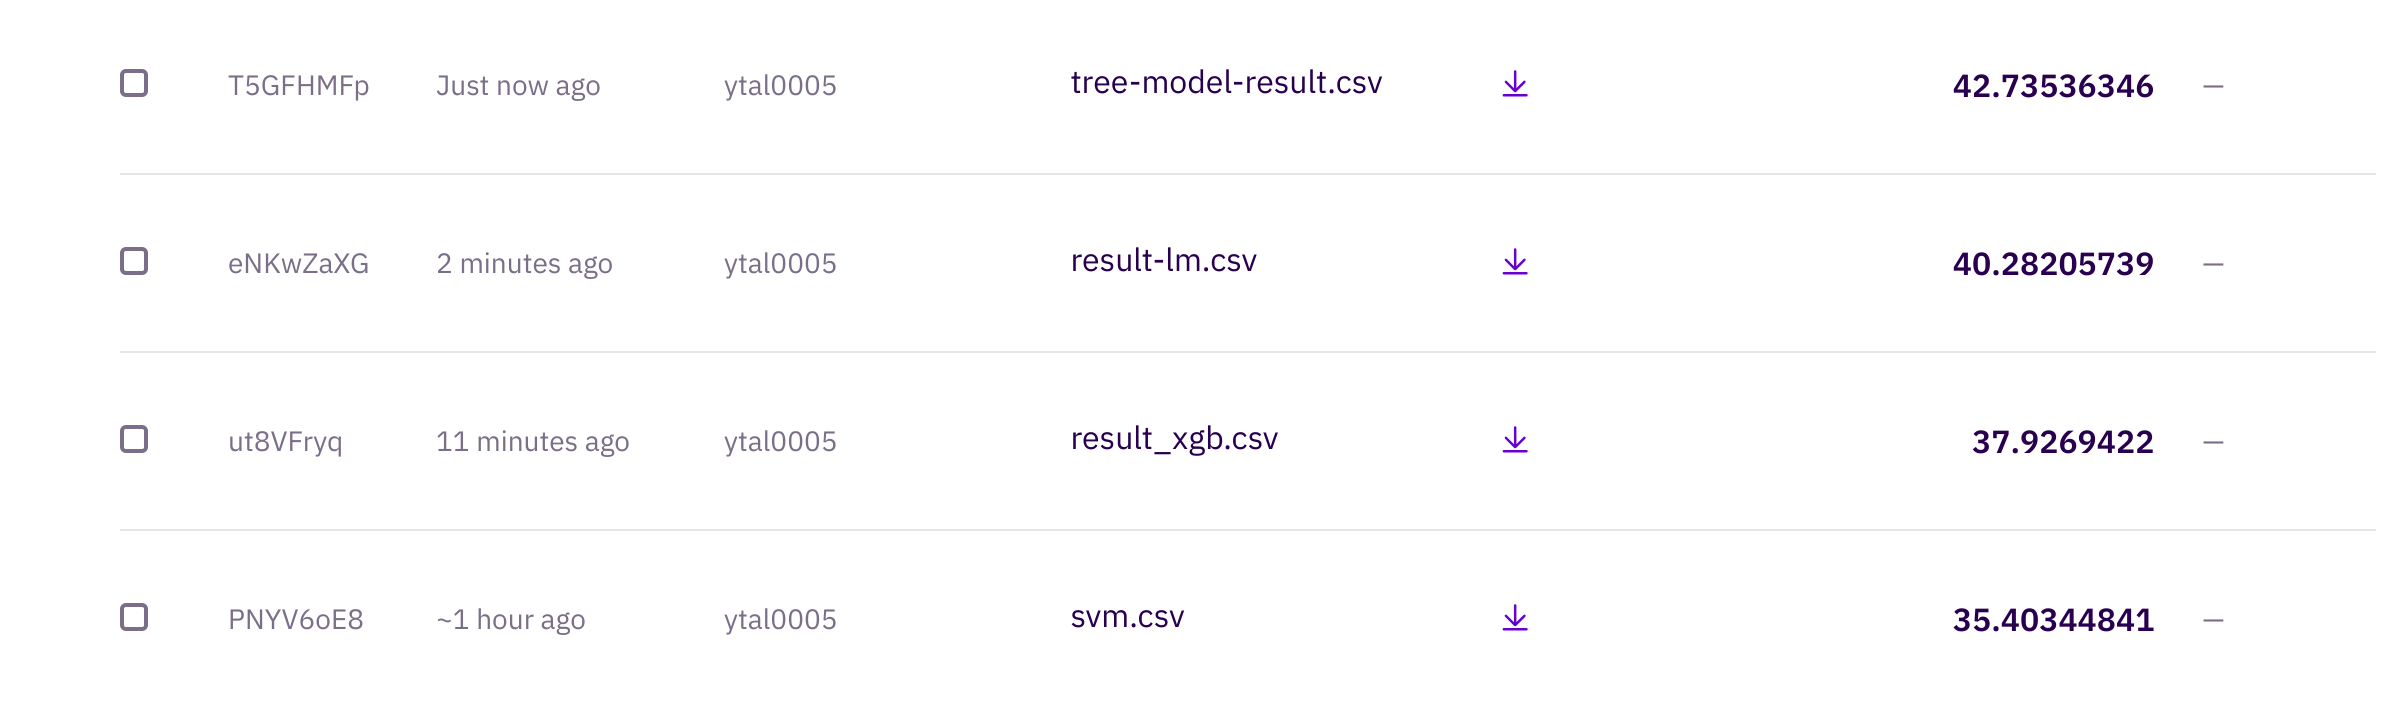

In [ ]:
# library(IRdisplay)
# display_jpeg(file = 'models-results.png')

### Predictions to submit on Zindi

In [127]:
# pred <- predict(lm_model, test_preprocessed)
# pred <- predict(tree_model, test_preprocessed)
# pred <- predict(svm_model, test_preprocessed)
pred <- predict(xgb_model, as.matrix(test_preprocessed))
result_df  <- data.frame(Place_ID.X.Date = test$Place_ID.X.Date, target = pred)
write.csv(result_df, "result.csv", row.names = FALSE)

In [128]:
res <- read.csv("result.csv" , stringsAsFactors = T)

In [129]:
res

Place_ID.X.Date,target
<fct>,<dbl>
0OS9LVX X 2020-01-02,32.16596
0OS9LVX X 2020-01-03,35.66242
0OS9LVX X 2020-01-04,31.83220
0OS9LVX X 2020-01-05,29.11505
0OS9LVX X 2020-01-06,25.11817
0OS9LVX X 2020-01-07,24.75876
0OS9LVX X 2020-01-08,33.51240
0OS9LVX X 2020-01-09,41.40377
0OS9LVX X 2020-01-10,37.39647


# **Task 5**

Since conditional entropy can be estimated by the MISE, our method will simply be to substract the MISE with all feature to the MISE without the selected feature.

* First we need to compute global MSE
* Then we compute MSE without the i_th feature to obtain the mutual conditional information

In [131]:
#xgboost parameters
param <- list("objective"="reg:squarederror",
             "eval_metric"="rmse",
             "nthread"=8,
             "max_depth"=30,
             "eta"=0.1,
             "gamma"=0,
             "subsample"=0.7,
             "colsample_bytree"=1,
             "min_child_weight"=12,
              "booster"="dart",
              "normalize_type"="forest"
             )

cv.nround <- min.rmse.idx #optimal nround observed earlier
cv.folds <- 10
size.cv <- floor(N/cv.folds)

cv.err <- rep(0, cv.folds) #vector for generalisation error

In [132]:
dim(X)
length(Y)

[1] 30557    37

[1] 30557

#### We only take the top 10 features in the ranking of the feature selection, we choose to use mRMR.

In [133]:
mRmR <- function(X_tr, Y_tr, n=0){
    # Computing the mutual_info between input variables and output variable on the training set
    mutual_info <- -0.5 * log(1 - cor(X_tr,Y_tr)^2)

    # Initialization : No variables are selected and all the variables are candidates
    selected<-c()
    candidates<-1:n

    #mRMR ranks the variables by taking account not only the mutual_info with the output, but also by avoiding redudant variables
    for (j in 1:n) {
        redundancy_score<-numeric(length(candidates))

        if (length(selected)>0) {
            # Compute the mutual_info between the selected variables and the candidates on the training set
            mutual_info_selected_candidates <- -0.5 * log(1 - cor(X_tr[,selected,drop=F],X_tr[,candidates,drop=F])^2)
            # Compute the mean mutual_info for each candidate variable, across the selected variables
            redundancy_score<-apply(mutual_info_selected_candidates,2,mean)
        }

        # mRMR: minimum Redundancy Maximum Relevancy
        mRMR_score<-mutual_info[candidates]-redundancy_score

        # Select the candidate variable that maximises the mRMR score
        selected_current<-candidates[which.max(mRMR_score)]
        selected<-c(selected,selected_current)

        # Remove the selected variables from the candidates
        candidates<-setdiff(candidates,selected_current)
    }

    ranking <- selected
    return(ranking)
}

ranking.top10 <- mRmR(X, Y, ncol(X))[1:10]
X.top10 <- X[,ranking.top10]

In [134]:
colnames(X.top10)
dim(X.top10)

[1] "L3_CO_CO_column_number_density"                     
 [2] "u_component_of_wind_10m_above_ground"               
 [3] "L3_NO2_tropospheric_NO2_column_number_density"      
 [4] "L3_AER_AI_sensor_altitude"                          
 [5] "L3_HCHO_HCHO_slant_column_number_density"           
 [6] "L3_SO2_absorbing_aerosol_index"                     
 [7] "L3_CLOUD_cloud_optical_depth"                       
 [8] "L3_SO2_SO2_slant_column_number_density"             
 [9] "L3_HCHO_tropospheric_HCHO_column_number_density_amf"
[10] "L3_CH4_aerosol_optical_depth"

[1] 30557    10

#### We start by calculating the conditional entropy H(y|X) wich translates to calculating the mean squared error using cross validation.

+/- 24 minutes.

In [135]:
for(i in 1:cv.folds){

    idx_ts<-(((i-1)*size.cv+1):(i*size.cv))  ### idx_ts represents the indices of the test set the i-th fold
    X_ts<-X.top10[idx_ts,]
    Y_ts<-Y[idx_ts]

    idx_tr<-setdiff(1:N,idx_ts) ### idx_tr represents  indices of the training sefor the i-th fold
    X_tr<-X.top10[idx_tr,]
    Y_tr<-Y[idx_tr]

    # Model fit
    xgbmodel <- xgboost(param=param,
                    data=data.matrix(X_tr),
                    label=data.matrix(Y_tr),
                    nround=cv.nround,
                    )
    # Model predict
    Y_hat_ts<- predict(xgbmodel,data.matrix(X_ts))

    # Cross validation error = MSE
    cv.err[i]<-mean((Y_hat_ts-Y_ts)^2)
   }
cv.err

[1]	train-rmse:71.299357 
[2]	train-rmse:65.969447 
[3]	train-rmse:61.199074 
[4]	train-rmse:56.947252 
[5]	train-rmse:53.142108 
[6]	train-rmse:49.784614 
[7]	train-rmse:46.800395 
[8]	train-rmse:44.139180 
[9]	train-rmse:41.775467 
[10]	train-rmse:39.675444 
[11]	train-rmse:37.791640 
[12]	train-rmse:36.134876 
[13]	train-rmse:34.675015 
[14]	train-rmse:33.335489 
[15]	train-rmse:32.147084 
[16]	train-rmse:31.080605 
[17]	train-rmse:30.110128 
[18]	train-rmse:29.249595 
[19]	train-rmse:28.435955 
[20]	train-rmse:27.701793 
[21]	train-rmse:27.013991 
[22]	train-rmse:26.414988 
[23]	train-rmse:25.846097 
[24]	train-rmse:25.352668 
[25]	train-rmse:24.870140 
[26]	train-rmse:24.410244 
[27]	train-rmse:24.004713 
[28]	train-rmse:23.601047 
[29]	train-rmse:23.273323 
[30]	train-rmse:22.923477 
[31]	train-rmse:22.560051 
[32]	train-rmse:22.330565 
[33]	train-rmse:22.034965 
[34]	train-rmse:21.783229 
[35]	train-rmse:21.537512 
[36]	train-rmse:21.267011 
[37]	train-rmse:21.050187 
[38]	train

[1]  894.4706 2142.2846 1513.2701 1207.4313 1030.0529 1408.1381 1479.7752
 [8] 1929.4962 1442.7318 1477.3441

In [136]:
H_y_X <- mean(cv.err) #global conditional entropy
print(paste("H(y|X) = ", H_y_X))

[1] "H(y|X) =  1452.49948047429"


#### Then we calculate H(y|$X^-i$) by using the same process as for H(y|X)  except that we remove a certain feature i form the dataset X.

In [137]:
number_feat<-ncol(X.top10)
candidates.cv.err<-matrix(0,nrow=number_feat,ncol=cv.folds)

for (candidate in 1:number_feat){ #n is the number of variable, thus candidate is the i_th feature to remove

    candidates<-setdiff(1:number_feat, candidate) # X⁻i

    for (i in 1:cv.folds) {
        idx_ts<-(((i-1)*size.cv+1):(i*size.cv))  ### idx_ts represents the indices of the test set the i-th fold
        X_ts<-X.top10[idx_ts, candidates]
        Y_ts<-Y[idx_ts]

        idx_tr<-setdiff(1:N,idx_ts) ### idx_tr represents  indices of the training sefor the i-th fold
        X_tr<-X.top10[idx_tr, candidates] # X⁻i
        Y_tr<-Y[idx_tr]

        # Model fit
        xgbmodel <- xgboost(param=param,
                        data=data.matrix(X_tr),
                        label=data.matrix(Y_tr),
                        nround=cv.nround,
                        )
        # Model predict
        Y_hat_ts<- predict(xgbmodel,data.matrix(X_ts))


        # Cross validation error = MSE
        candidates.cv.err[candidate, i]<-mean((Y_hat_ts-Y_ts)^2)
    }
}
H_y_Xi<-apply(candidates.cv.err,1,mean)

[1]	train-rmse:71.414693 
[2]	train-rmse:66.175087 
[3]	train-rmse:61.530874 
[4]	train-rmse:57.359330 
[5]	train-rmse:53.668930 
[6]	train-rmse:50.368738 
[7]	train-rmse:47.432396 
[8]	train-rmse:44.867896 
[9]	train-rmse:42.562641 
[10]	train-rmse:40.541720 
[11]	train-rmse:38.718643 
[12]	train-rmse:37.100950 
[13]	train-rmse:35.669719 
[14]	train-rmse:34.398209 
[15]	train-rmse:33.255071 
[16]	train-rmse:32.197349 
[17]	train-rmse:31.285325 
[18]	train-rmse:30.414009 
[19]	train-rmse:29.652552 
[20]	train-rmse:28.961735 
[21]	train-rmse:28.301746 
[22]	train-rmse:27.722823 
[23]	train-rmse:27.187105 
[24]	train-rmse:26.676590 
[25]	train-rmse:26.195170 
[26]	train-rmse:25.737576 
[27]	train-rmse:25.328141 
[28]	train-rmse:24.945825 
[29]	train-rmse:24.587088 
[30]	train-rmse:24.279385 
[31]	train-rmse:23.961964 
[32]	train-rmse:23.642809 
[33]	train-rmse:23.326421 
[34]	train-rmse:23.035471 
[35]	train-rmse:22.724401 
[36]	train-rmse:22.453876 
[37]	train-rmse:22.200464 
[38]	train

In [138]:
I_xiy_Xi <- H_y_Xi-H_y_X # mutual information
numb_feat <- length(I_xiy_Xi)
for (i in 1:numb_feat){
    best_feature <- which.min(I_xiy_Xi)
    name_features <- colnames(X.top10)
    print(paste("Rank ", i, "feature: ", name_features[best_feature], " ; mutual information = ", I_xiy_Xi[best_feature]))
    I_xiy_Xi <- I_xiy_Xi[setdiff(1:length(I_xiy_Xi), best_feature)]
}

[1] "Rank  1 feature:  L3_SO2_SO2_slant_column_number_density  ; mutual information =  9.80356859570566"
[1] "Rank  2 feature:  L3_HCHO_tropospheric_HCHO_column_number_density_amf  ; mutual information =  18.0289166051803"
[1] "Rank  3 feature:  L3_SO2_absorbing_aerosol_index  ; mutual information =  34.2841918001654"
[1] "Rank  4 feature:  L3_SO2_absorbing_aerosol_index  ; mutual information =  41.1922198179809"
[1] "Rank  5 feature:  L3_HCHO_HCHO_slant_column_number_density  ; mutual information =  44.7408511175236"
[1] "Rank  6 feature:  L3_NO2_tropospheric_NO2_column_number_density  ; mutual information =  56.7265447034238"
[1] "Rank  7 feature:  L3_AER_AI_sensor_altitude  ; mutual information =  77.6455160246096"
[1] "Rank  8 feature:  u_component_of_wind_10m_above_ground  ; mutual information =  87.0149396974455"
[1] "Rank  9 feature:  L3_CO_CO_column_number_density  ; mutual information =  178.390199731688"
[1] "Rank  10 feature:  L3_CO_CO_column_number_density  ; mutual informa